# ✍️ Lab 05: Can an LLM Judge Replace Your Analysts? 🔬

## Module 05 — Evaluating Generative Outputs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05-generative-outputs-lab.ipynb)

<center><font size="6"><b>"It agrees with the analysts 90% of the time."</b></font></center>

Should it replace the analysts? You'll <mark>sign off or block it, with evidence</mark>. ⏱️ Part 1: ~35 min.

| | |
|---|---|
| ⏱️ **Time** | 60–75 min core · +45 min for the five challenges |
| 🎚️ **Level** | Intermediate |
| 🔑 **Keys needed** | None. Runs offline with a simulated judge (`PROVIDER = "mock"`). Optional: an OpenAI or Anthropic key to run a real judge |
| 🧰 **Tools** | Python, `pandas`, `scikit-learn` (Cohen's κ), `pydantic` (verdict schema), `matplotlib` |
| 🏁 **You'll leave with** | A binary judge validated with TPR/TNR/κ, a three-probe bias kit, an evidence-based SHIP/BLOCK call, and a scored prediction card |

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

## 🧭 Overview

<!-- img: pipeline.png -->
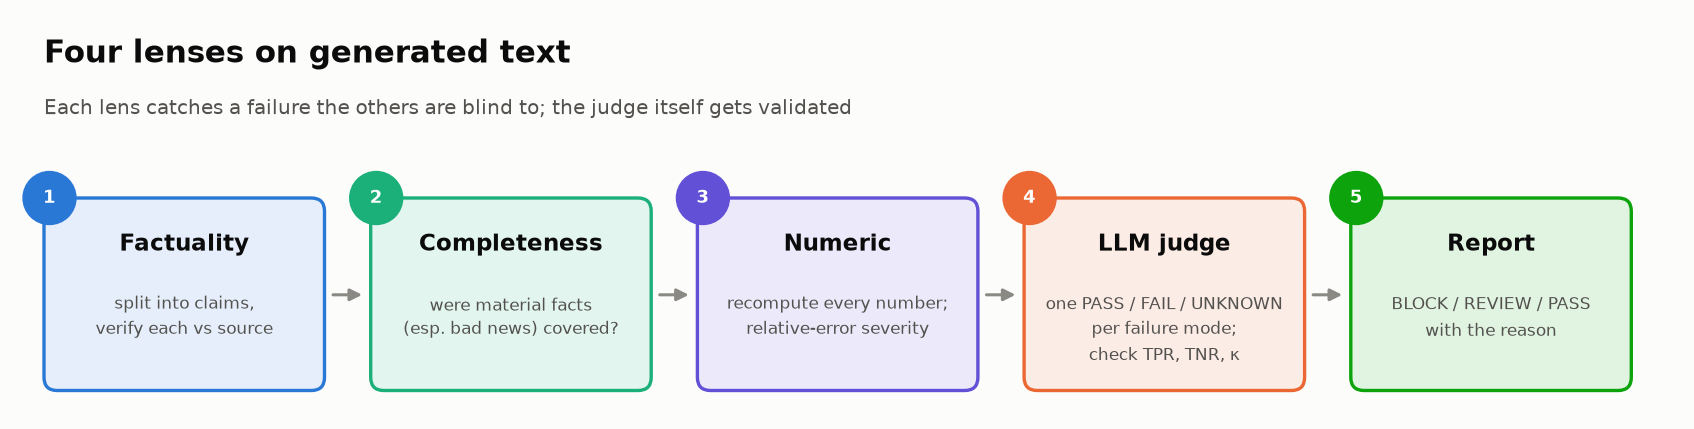

<details>
<summary>🗺️ The four acts</summary>

| Act | Tasks | Question it answers |
|---|---|---|
| 1. Deterministic checks | 2–6 | Are the claims true? Is anything material missing? Is the math right? |
| 2. The LLM judge | 7–8 | Can one PASS/FAIL check per failure mode catch what code can't? |
| 3. Judge the judge | 9–11 | How often is it wrong? Where? What sways it? |
| 4. The decision | 12 | Should the judge replace human review? |
</details>

<details>
<summary>📖 Jargon decoder: 34 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Earnings summary** | A short write-up of a company's quarterly results that investors act on | Hook, Task 2 |
| **Revenue · net income · net loss** | Sales · profit after every cost · a negative net income | Task 2 |
| **QoQ · YoY** | Quarter-over-quarter (vs the previous quarter) · year-over-year (vs the same quarter last year) | Tasks 2, 6 |
| **EPS** | Earnings per share: net income ÷ shares outstanding | Tasks 2, 6 |
| **Gross · operating margin** | Share of revenue left after direct costs · after all operating costs | Task 2 |
| **Guidance** | Management's forecast range for next quarter's results | Task 2 |
| **Debt covenant waiver** | Lenders agree not to enforce a loan condition the company broke or was about to break. A distress signal | Hook, Tasks 3, 5 |
| **Leverage** | Debt relative to what the company can pay it with; this lab's rubric flags debt above 2× cash | Tasks 8–9 |
| **Material** | Big enough to change a reasonable reader's decision | Tasks 2, 5, 6 |
| **Claim · atomic claim** | One checkable statement · one subject, one metric, one value | Task 4 |
| **Fabrication · distortion · conflation** | Three kinds of hallucination: an invented detail · a real fact with wrong details · facts mixed across sources or periods | Task 4 |
| **Factuality vs completeness** | "Is what it says true?" vs "Does it say everything material?" | Tasks 4–5 |
| **Deterministic check** | Code that gives the same answer every time (a regex, a recomputation); no model involved | Tasks 4–6 |
| **Entailment** | Whether a text actually *states or implies* a fact. Word overlap can't tell "a waiver was obtained" from "no waiver was obtained"; an entailment check can | Task 5, Challenge 1 |
| **Absolute · relative error** | \|stated − actual\| · that, divided by \|actual\| | Task 6 |
| **Percentage points (pp)** | The plain difference between two percentages: 25% vs 20% is 5 pp apart, a 25% *relative* error | Tasks 6, 11 |
| **Failure mode** | One specific, observable way an output goes wrong ("omits a material risk") | Tasks 2, 7 |
| **Rubric** | The written criteria a judge grades against | Task 7 |
| **Likert scale** | A 1–5 rating ("how good is it?") | Tasks 7–8 |
| **LLM judge** | A model given the source, the output and one rubric check, returning a verdict | Task 8 |
| **Structured output · Pydantic** | The API forces the reply to match a schema · the Python library used to define that schema as a class | Task 8 |
| **Critique-then-verdict** | The judge writes its evidence before its decision, so the decision is conditioned on it | Task 8 |
| **UNKNOWN (abstention)** | The judge declines to decide; a human does | Tasks 8–9 |
| **Meta-evaluation** | Evaluating the evaluator against expert labels | Task 9 |
| **TP · FN · FP · TN** | With FAIL as "positive": caught defect · missed defect · false alarm · correct pass | Task 9 |
| **TPR (recall) · TNR (specificity)** | Share of real failures the judge catches · share of good outputs it passes | Task 9 |
| **Raw agreement · base rate** | Share of verdicts that match · how often a rater says FAIL at all | Task 9 |
| **Cohen's κ (kappa)** | Agreement left after subtracting what the two raters' base rates would produce by luck; 0 = chance, 1 = perfect | Task 9 |
| **95% confidence interval (Wilson)** | The range of true rates consistent with what you observed; Wilson is the version that behaves on small samples | Task 9 |
| **Dev · test split** | Labels you tune a judge on · held-out labels you score it on once | Task 9, Challenge 3 |
| **Slicing** | Grouping errors by an input feature (format, position, type) to find the pattern | Task 10 |
| **Pairwise judging · position / verbosity / style bias** | The judge picks the better of two outputs · it favours the first slot / longer text / markdown formatting, regardless of content | Task 11 |
| **Self-preference · PoLL** | A judge favouring its own model family · a "panel of LLM evaluators" that votes | Task 11, Stretch B |
| **Defense in depth · IRS OPR** | Independent layers, so one layer's blind spot is another's catch · the IRS office that regulates tax practitioners | Task 12 |

</details>

<details>
<summary>🎯 Objectives · setup</summary>

## 🎯 Learning Objectives

Score factuality, completeness and numbers; build a binary judge; validate it with TPR, TNR and κ; probe its bias; make a ship call.

## 📋 Prerequisites

Modules 01–02, pandas, some prompt engineering.

## ⏱️ Estimated Time

60–75 min for Tasks 1–12 across both parts.

## 🧪 Environment and Setup

Offline, no keys (`PROVIDER = "mock"`). A real judge needs `PROVIDER = "openai"` or `"anthropic"` and a key in 🔑 Secrets.

## 📖 Scenario

LLM-written earnings summaries that portfolio managers trade on. One said 15% growth (truth: 8%).
</details>

---

## Task 1: Environment Setup 🛠️

<big><b>Everything downstream reads one config cell; a model ID typed twice is next quarter's silent bug.</b></big>

> 🎯 **Goal:** imports, one config cell, and the lab kit.<br>
> ❓ **The question:** where does reproducibility come from, if not `temperature=0`?<br>
> 👀 **Watch for:** `PROVIDER = 'mock'`: everything runs offline.

▶️ **Run** the next three cells: 📦 install (only needed for a real judge), ⚙️ imports + config, 🎨 lab kit (collapsed).

In [ ]:
%%capture
# Only needed for a REAL judge (PROVIDER = "openai" or "anthropic").
# pandas, numpy, scikit-learn, matplotlib and pydantic are preinstalled in Colab.
!pip install -U openai anthropic

In [ ]:
import json                      # source data -> judge prompt
import re                        # claim extraction and text parsing
import hashlib                   # deterministic "noise" for the simulated judges
from collections import defaultdict
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field          # the judge's verdict schema (structured output)
from sklearn.metrics import cohen_kappa_score  # agreement beyond chance

# ── Configuration: the ONLY place model names live ─────────────────────────────
PROVIDER = "mock"                              # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_JUDGE_MODEL = "gpt-6-luna"              # stronger judge: "gpt-6.1-sol"
ANTHROPIC_JUDGE_MODEL = "claude-haiku-5-5"     # stronger judge: "claude-sonnet-5-5"
SEED = 7                                       # fixes the synthetic data (a real judge is never deterministic)

pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 70)
print(f"✅ Imports OK · PROVIDER = {PROVIDER!r}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

✋ **Your turn (warm-up):** this is how every exercise works. Run the collapsed answer key, then fill the blank in the cell under it.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_overstatement = (15 - 8) / 8

In [ ]:
# ✋ Your turn (warm-up): the hook's summary said revenue grew 15%; it grew 8%.
#    By what fraction of the TRUE growth rate did the summary overstate it?
stated, actual = 15, 8

my_overstatement = ...   # ✏️ one expression using stated and actual

check("Warm-up: how wrong was 15% vs 8%?", my_overstatement, _ref_overstatement,
      hint="Size the gap against the truth: divide (stated − actual) by the true value, not the stated one.",
      success=f"{_ref_overstatement:.1%}: the summary nearly doubled real growth, and '15%' reads as fluently as '8%'. Task 6 runs this check on every number.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `✅ Imports OK · PROVIDER = 'mock'` and `🎨 Lab kit loaded…`. `ModuleNotFoundError`: run the install cell, restart.
</details>

In [ ]:
# @title ❓ Quick check: why does this lab never send temperature=0 to the judge?
answer = "— pick one —"  # @param ["— pick one —", "A) Temperature 0 would make the judge too strict", "B) It does not make outputs reproducible, and some APIs now reject it", "C) The mock ignores it, so sending it would be wasted", "D) It makes the judge deterministic, but slower"]
quiz('Why no temperature=0', answer, correct="B",
     why="Anthropic rejects temperature (HTTP 400 since API version 2026-10-21), and it never bought reproducibility. Here reproducibility comes from the mock and fixed seeds; trust in a real judge comes from validating it (Task 9).",
     wrong={"A": 'Temperature changes sampling randomness, not strictness.',
          "C": 'True for the mock, but the real-provider code skips it too, on purpose.',
          "D": 'In a Thinking Machines test (2025), 1,000 identical temperature-0 requests gave 80 distinct completions.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Reproducibility comes from fixtures and seeds; trust in a judge comes only from validating it.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 1 of 4 (Tasks 2–6): deterministic checks.

## Task 2: Load the Financial Analysis Dataset 📊

<big><b>Every evaluator compares a summary with its source.</b></big>

> 🎯 **Goal:** six summaries, their source data, two kinds of expert label.<br>
> ❓ **The question:** if you ship everything rated 3+, is it safe?<br>
> 👀 **Watch for:** two labels from the same expert that disagree.

<details><summary>📂 What each summary carries</summary>

`source_data` (ground truth) · `generated_summary` (what you grade) · `key_facts` (Task 5) · `numeric_claims` (Task 6) · `human_quality_score` (1–5) · `human_labels` (PASS/FAIL per **failure mode**: one observable way a summary goes wrong)
</details>

▶️ **Run** (code hidden, nothing to read): loads the six summaries.

In [ ]:
# @title 🧰 Dataset: 6 summaries with source data, key facts, numeric claims and expert labels (hidden · 308 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# Synthetic financial analysis evaluation dataset
# Each entry represents one quarterly summary generated by an LLM.
#
# STRUCTURE OF EACH ENTRY:
#   - source_data: The ACTUAL numbers (our ground truth)
#   - generated_summary: What the LLM wrote (what we're checking)
#   - key_facts: Facts that SHOULD appear (for completeness scoring)
#   - numeric_claims: Specific numbers to verify (stated vs actual)
#   - human_quality_score: Expert rating for comparison to our automated scores
# ──────────────────────────────────────────────────────────────

financial_dataset = [
    {
        "id": 1,
        "company": "TechFlow Inc.",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 142_000_000,
            "revenue_prev_quarter": 128_000_000,
            "revenue_prev_year": 118_000_000,
            "operating_expenses": 98_000_000,
            "net_income": 31_000_000,
            "net_income_prev_quarter": 27_000_000,
            "gross_margin_pct": 45.2,
            "operating_margin_pct": 31.0,
            "eps": 2.15,
            "eps_prev_quarter": 1.88,
            "total_debt": 85_000_000,
            "cash_on_hand": 210_000_000,
            "headcount": 3_200,
            "guidance_next_quarter_revenue_low": 148_000_000,
            "guidance_next_quarter_revenue_high": 155_000_000,
            "notable_events": ["Acquired DataSync Corp for $45M", "Launched CloudEdge platform"]
        },
        # This summary is HIGH QUALITY — accurate, complete, well-framed
        "generated_summary": "TechFlow Inc. reported strong Q3 2025 results with revenue of $142M, up 10.9% quarter-over-quarter and 20.3% year-over-year. Net income reached $31M with EPS of $2.15, representing 14.4% growth over Q2. The company maintains a healthy balance sheet with $210M in cash against $85M in total debt. Operating margin was 31.0% with gross margins at 45.2%. During the quarter, TechFlow acquired DataSync Corp for $45M and launched the CloudEdge platform. Management guided Q4 revenue to $148M-$155M, signaling continued momentum.",
        "key_facts": [
            "Revenue of $142M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $31M",
            "EPS of $2.15",
            "Cash position of $210M",
            "Debt position of $85M",
            "Acquisition of DataSync Corp",
            "Launch of CloudEdge platform",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 142_000_000, "actual": 142_000_000},
            "qoq_growth_pct": {"stated": 10.9, "actual": 10.94},
            "yoy_growth_pct": {"stated": 20.3, "actual": 20.34},
            "eps": {"stated": 2.15, "actual": 2.15},
            "eps_growth_pct": {"stated": 14.4, "actual": 14.36},
            "net_income": {"stated": 31_000_000, "actual": 31_000_000}
        },
        "human_quality_score": 5  # Expert says: excellent summary
    },
    {
        "id": 2,
        "company": "GreenLeaf Energy",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 89_000_000,
            "revenue_prev_quarter": 94_000_000,
            "revenue_prev_year": 82_000_000,
            "operating_expenses": 78_000_000,
            "net_income": 4_500_000,
            "net_income_prev_quarter": 11_000_000,
            "gross_margin_pct": 28.1,
            "operating_margin_pct": 12.4,
            "eps": 0.38,
            "eps_prev_quarter": 0.92,
            "total_debt": 220_000_000,
            "cash_on_hand": 45_000_000,
            "headcount": 1_800,
            "guidance_next_quarter_revenue_low": 91_000_000,
            "guidance_next_quarter_revenue_high": 97_000_000,
            "notable_events": ["Debt covenant waiver obtained from lenders", "CEO transition announced"]
        },
        # ⚠️ This summary is MISLEADING — everything stated is true,
        # but it OMITS critical negative information (declining revenue,
        # plummeting income, debt covenant waiver, CEO leaving)
        "generated_summary": "GreenLeaf Energy posted Q3 2025 revenue of $89M, growing 8.5% year-over-year. Operating margin remained healthy at 12.4%. EPS came in at $0.38. The company has $45M in cash and continues to invest in renewable infrastructure expansion. Management expects Q4 revenue between $91M and $97M, reflecting confidence in their growth strategy.",
        "key_facts": [
            "Revenue of $89M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Significant net income decline",
            "EPS of $0.38 (sharp drop from $0.92)",
            "High debt level of $220M",
            "Low cash position of $45M relative to debt",
            "Debt covenant waiver obtained",
            "CEO transition announced",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 89_000_000, "actual": 89_000_000},
            "yoy_growth_pct": {"stated": 8.5, "actual": 8.54},
            "operating_margin_pct": {"stated": 12.4, "actual": 12.4},
            "eps": {"stated": 0.38, "actual": 0.38}
        },
        "human_quality_score": 2  # Expert says: dangerously misleading
    },
    {
        "id": 3,
        "company": "MedVault Health",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 210_000_000,
            "revenue_prev_quarter": 198_000_000,
            "revenue_prev_year": 175_000_000,
            "operating_expenses": 165_000_000,
            "net_income": 33_000_000,
            "net_income_prev_quarter": 29_000_000,
            "gross_margin_pct": 52.8,
            "operating_margin_pct": 21.4,
            "eps": 1.72,
            "eps_prev_quarter": 1.51,
            "total_debt": 150_000_000,
            "cash_on_hand": 320_000_000,
            "headcount": 5_400,
            "guidance_next_quarter_revenue_low": 218_000_000,
            "guidance_next_quarter_revenue_high": 225_000_000,
            "notable_events": ["FDA approval for DiagnostiQ AI platform", "Expanded into 3 new European markets"]
        },
        # ⚠️ This summary has a NUMERIC ERROR — states 25% YoY growth
        # but the actual calculation is (210-175)/175 = 20.0%
        "generated_summary": "MedVault Health delivered solid Q3 2025 results. Revenue hit $210M, up 6.1% from Q2 and 25% year-over-year — a strong acceleration driven by the new DiagnostiQ AI platform which received FDA approval during the quarter. Net income was $33M with EPS of $1.72. Gross margins expanded to 52.8%, among the best in the health-tech sector. The company expanded into 3 new European markets and holds a fortress balance sheet with $320M in cash versus $150M in debt. Operating expenses rose to $165M reflecting investment in European expansion. Q4 guidance of $218M-$225M suggests management expects mid-single-digit sequential growth.",
        "key_facts": [
            "Revenue of $210M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $33M",
            "EPS of $1.72",
            "Gross margin of 52.8%",
            "FDA approval for DiagnostiQ AI",
            "European market expansion",
            "Cash position of $320M",
            "Debt of $150M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 210_000_000, "actual": 210_000_000},
            "qoq_growth_pct": {"stated": 6.1, "actual": 6.06},
            "yoy_growth_pct": {"stated": 25.0, "actual": 20.0},  # <-- THE ERROR: 25% vs 20%
            "eps": {"stated": 1.72, "actual": 1.72},
            "gross_margin_pct": {"stated": 52.8, "actual": 52.8},
            "net_income": {"stated": 33_000_000, "actual": 33_000_000}
        },
        "human_quality_score": 3  # Expert says: good but has a numeric error
    },
    {
        "id": 4,
        "company": "UrbanLogix",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 67_000_000,
            "revenue_prev_quarter": 71_000_000,
            "revenue_prev_year": 63_000_000,
            "operating_expenses": 72_000_000,
            "net_income": -8_500_000,
            "net_income_prev_quarter": -3_200_000,
            "gross_margin_pct": 18.7,
            "operating_margin_pct": -7.5,
            "eps": -0.62,
            "eps_prev_quarter": -0.23,
            "total_debt": 180_000_000,
            "cash_on_hand": 52_000_000,
            "headcount": 2_100,
            "guidance_next_quarter_revenue_low": 70_000_000,
            "guidance_next_quarter_revenue_high": 75_000_000,
            "notable_events": ["Restructuring plan announced — 15% workforce reduction", "Entered partnership with CityGrid for smart delivery"]
        },
        # ⚠️ This summary SPINS negative news positively —
        # calls widening losses "strategic investments" and omits the layoffs
        "generated_summary": "UrbanLogix reported Q3 2025 revenue of $67M, up 6.3% year-over-year, demonstrating resilience in the logistics space. While operating expenses of $72M exceeded revenue, the company's strategic investments are positioning it for long-term growth. EPS was -$0.62. The company announced an exciting partnership with CityGrid for smart delivery solutions and has $52M in cash to fund operations. Management guided Q4 revenue to $70M-$75M.",
        "key_facts": [
            "Revenue of $67M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Net loss of $8.5M (widening losses)",
            "Negative operating margin of -7.5%",
            "EPS of -$0.62 (worsening from -$0.23)",
            "High debt of $180M vs $52M cash",
            "15% workforce restructuring",
            "CityGrid partnership",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 67_000_000, "actual": 67_000_000},
            "yoy_growth_pct": {"stated": 6.3, "actual": 6.35},
            "operating_expenses": {"stated": 72_000_000, "actual": 72_000_000},
            "eps": {"stated": -0.62, "actual": -0.62}
        },
        "human_quality_score": 2  # Expert says: misleading positive spin
    },
    {
        "id": 5,
        "company": "NexaPay Financial",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 325_000_000,
            "revenue_prev_quarter": 310_000_000,
            "revenue_prev_year": 280_000_000,
            "operating_expenses": 245_000_000,
            "net_income": 58_000_000,
            "net_income_prev_quarter": 52_000_000,
            "gross_margin_pct": 61.3,
            "operating_margin_pct": 24.6,
            "eps": 3.42,
            "eps_prev_quarter": 3.07,
            "total_debt": 120_000_000,
            "cash_on_hand": 480_000_000,
            "headcount": 8_200,
            "guidance_next_quarter_revenue_low": 335_000_000,
            "guidance_next_quarter_revenue_high": 345_000_000,
            "notable_events": ["Launched instant cross-border payments in 12 new countries", "Regulatory approval for crypto custody services"]
        },
        # ⚠️ This summary has FABRICATED details — says 15 countries
        # (actual: 12) and EPS growth of 22% (actual: ~11.4%)
        "generated_summary": "NexaPay Financial posted exceptional Q3 2025 results with revenue of $325M, up 4.8% sequentially and 16.1% year-over-year. Net income surged to $58M, driving EPS to $3.42 — a 22% increase versus Q2. Gross margins of 61.3% and operating margins of 24.6% reflect excellent unit economics. The company launched instant cross-border payments in 15 new countries and received regulatory approval for crypto custody services. With $480M in cash and only $120M in debt, NexaPay has significant capacity for M&A. Q4 guidance of $335M-$345M represents 3-6% sequential growth. One risk to watch: operating expenses of $245M grew faster than revenue on a percentage basis.",
        "key_facts": [
            "Revenue of $325M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $58M",
            "EPS of $3.42",
            "Gross margin of 61.3%",
            "Operating margin of 24.6%",
            "Cross-border payments expansion",
            "Crypto custody regulatory approval",
            "Strong cash position ($480M vs $120M debt)",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 325_000_000, "actual": 325_000_000},
            "qoq_growth_pct": {"stated": 4.8, "actual": 4.84},
            "yoy_growth_pct": {"stated": 16.1, "actual": 16.07},
            "eps": {"stated": 3.42, "actual": 3.42},
            "eps_growth_pct": {"stated": 22.0, "actual": 11.40},  # <-- WRONG: 22% vs 11.4%
            "net_income": {"stated": 58_000_000, "actual": 58_000_000},
            "countries_expanded": {"stated": 15, "actual": 12}  # <-- FABRICATED: 15 vs 12
        },
        "human_quality_score": 3  # Expert says: mostly good but has errors
    },
    {
        "id": 6,
        "company": "SkyBridge Telecom",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 195_000_000,
            "revenue_prev_quarter": 192_000_000,
            "revenue_prev_year": 188_000_000,
            "operating_expenses": 170_000_000,
            "net_income": 18_000_000,
            "net_income_prev_quarter": 16_500_000,
            "gross_margin_pct": 38.5,
            "operating_margin_pct": 12.8,
            "eps": 1.05,
            "eps_prev_quarter": 0.96,
            "total_debt": 340_000_000,
            "cash_on_hand": 75_000_000,
            "headcount": 4_600,
            "guidance_next_quarter_revenue_low": 196_000_000,
            "guidance_next_quarter_revenue_high": 202_000_000,
            "notable_events": ["5G network coverage reached 80% of target markets", "Signed 10-year spectrum lease agreement"]
        },
        # This summary is DECENT — accurate but misses the $340M debt position
        "generated_summary": "SkyBridge Telecom delivered steady Q3 2025 results with revenue of $195M, a modest 1.6% increase over Q2 and 3.7% year-over-year growth. Net income of $18M and EPS of $1.05 show continued profitability. The company achieved a major milestone with 5G coverage reaching 80% of target markets and secured a 10-year spectrum lease. Operating margin of 12.8% was stable. Cash on hand stands at $75M. Q4 guidance of $196M–$202M suggests continued steady performance.",
        "key_facts": [
            "Revenue of $195M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $18M",
            "EPS of $1.05",
            "5G coverage milestone (80%)",
            "Spectrum lease agreement",
            "Debt position of $340M",
            "Cash position of $75M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 195_000_000, "actual": 195_000_000},
            "qoq_growth_pct": {"stated": 1.6, "actual": 1.56},
            "yoy_growth_pct": {"stated": 3.7, "actual": 3.72},
            "eps": {"stated": 1.05, "actual": 1.05},
            "net_income": {"stated": 18_000_000, "actual": 18_000_000}
        },
        "human_quality_score": 4  # Expert says: solid but missing debt info
    }
]

# ── The expert's BINARY labels, one per failure mode (used from Task 8 on) ──
# Same expert, different question: not "how good is it, 1-5?" but "does it show failure X, yes or no?"
MODES = ["numbers_correct", "grounded", "risks_disclosed", "balanced_framing"]
HUMAN_LABELS = {
    1: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    2: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    3: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    4: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    5: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    6: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "PASS"},
}
for item in financial_dataset:
    item["human_labels"] = HUMAN_LABELS[item["id"]]


▶️ **Run:** one row per summary → read the *human 1-5* column and the last tile.

In [ ]:
# A first look at the six summaries, the way the expert saw them: one 1–5 score each.
overview = pd.DataFrame([{
    "id": it["id"], "company": it["company"],
    "revenue": f"${it['source_data']['revenue'] / 1e6:.0f}M",
    "net income": f"${it['source_data']['net_income'] / 1e6:.1f}M",
    "key facts": len(it["key_facts"]), "numeric claims": len(it["numeric_claims"]),
    "human 1-5": it["human_quality_score"],
} for it in financial_dataset]).set_index("id")
print(f"Loaded {len(financial_dataset)} financial analysis summaries.\n")
print(overview.to_string())

scores = [it["human_quality_score"] for it in financial_dataset]
tiles([
    ("Summaries", len(financial_dataset), "Q3 2025 earnings", None),
    ("Expert score range", f"{min(scores)}–{max(scores)}", "holistic 1–5 rating", None),
    ("Rated 3 or higher", f"{sum(s >= 3 for s in scores)} of {len(scores)}", "would all of these be safe to send?", "warning"),
])


🔍 **What just happened:** a "ship anything ≥ 3" rule sends **four** summaries to portfolio managers.

✋ **Your turn:** the same expert also labeled each summary PASS/FAIL per failure mode. Check whether the two label types agree.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_all_pass_names = [it["company"] for it in financial_dataset if all(v == "PASS" for v in it["human_labels"].values())]
_ref_all_pass = len(_ref_all_pass_names)

In [ ]:
# ✋ Your turn: the expert's PASS/FAIL labels, one per failure mode. TechFlow's look like this:
print(financial_dataset[0]["human_labels"])

my_all_pass = ...   # ✏️ how many of the 6 summaries are PASS on all four labels?

check("Summaries that pass every failure-mode label", my_all_pass, _ref_all_pass,
      hint="A summary counts only if every value in its human_labels dict is 'PASS'. all() per summary, sum() over the six.",
      success=f"{_ref_all_pass} of 6 ({', '.join(_ref_all_pass_names)}), yet the same expert rated {sum(s >= 3 for s in scores)} of 6 at 3 or higher. A 1–5 score blends a material failure into 'decent'.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** A 6-row table; tiles end with **Rated 3 or higher: 4 of 6**.
</details>

In [ ]:
# @title ❓ Quick check: the expert rated SkyBridge 4/5 and labeled risks_disclosed FAIL. Which label should gate the release?
answer = "— pick one —"  # @param ["— pick one —", "A) The 4 out of 5: it is the expert's overall judgment", "B) Average the two into one score", "C) The FAIL: a gate needs to know which failure happened"]
quiz('Which label gates a release?', answer, correct="C",
     why="One blocking FAIL blocks. SkyBridge omits $340M of debt against $75M of cash; its 4/5 hides that.",
     wrong={"A": "An overall score blends a material omission into 'good'.",
          "B": "Averaging is how one material error becomes 'a decent 3.5' (Task 8)."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>A 1–5 score says how it feels; a PASS/FAIL per failure mode says what broke.</b></font>

</td></tr></table>

---

## Task 3: 🔍 Think First — What Makes a Financial Summary Trustworthy?

<big><b>An evaluator catches only the errors someone named first.</b></big>

> 🎯 **Goal:** rank the ways a summary can be wrong, before building anything.<br>
> ❓ **The question:** can a summary mislead with every sentence true?<br>
> 👀 **Watch for:** what GreenLeaf leaves out.

GreenLeaf: *"Q3 revenue of ＄89M, growing 8.5% year-over-year. Operating margin remained healthy at 12.4%. EPS came in at ＄0.38…"* Its source: revenue **fell** from ＄94M, income fell 59%, ＄220M of debt, a **covenant waiver**, a departing **CEO**. <font color="#d03b3b"><b>⚠️ Every sentence is true; the picture is false.</b></font>

<!-- img: comic-technically-true.png -->
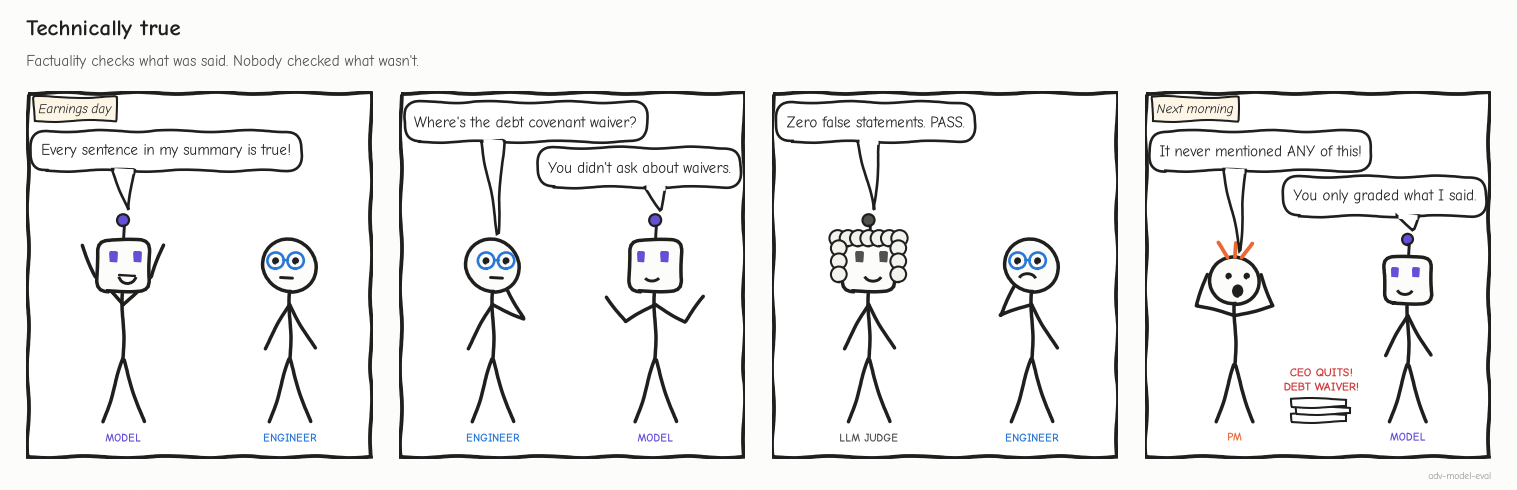

<sub>🖼️ *A factuality score only grades what was said.*</sub>

✋ **Your turn:** rank five errors by how much damage they do.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _rank_ok(r):
    try:
        r = [str(x).strip().upper() for x in r]
        return sorted(r) == list("ABCDE") and set(r[:2]) == {"B", "C"} and set(r[3:]) == {"A", "D"}
    except TypeError:
        return False

In [ ]:
# ✋ Your turn: rank these errors from MOST to LEAST dangerous to a portfolio manager.
ERRORS = {"A": "Growth rate rounded: 10.94% written as 10.9%",
          "B": "A debt covenant waiver left out",
          "C": "Revenue said to grow when it fell quarter-over-quarter",
          "D": "Revenue of $142M written as $143M",
          "E": "Upbeat words for declining metrics"}

my_ranking = ...   # ✏️ all five letters, most dangerous first, e.g. ["E", "D", "C", "B", "A"]

check("Rank the damage", my_ranking, ok=not todo(my_ranking) and _rank_ok(my_ranking),
      hint="Ask of each: would a reader trade differently? Two change the decision, one misleads by tone, two are rounding.",
      success="B and C change the decision, E misleads by tone, A and D are rounding. An exact-match number check flags A and D loudest and never sees B.")

✍️ **Your reflection** (open; double-click to edit): in what distinct ways can a summary be wrong? Name four dimensions you'd score.

*Your answer…*

In [ ]:
# @title ❓ Quick check: GreenLeaf has no false sentence. Which evaluator can catch it?
answer = "— pick one —"  # @param ["— pick one —", "A) A completeness check against the material facts it must cover", "B) A stricter fact-checker that verifies every sentence", "C) A fluency or readability score", "D) Nothing: if every sentence is true, the summary is fine"]
quiz('What catches GreenLeaf?', answer, correct="A",
     why="GreenLeaf fails by omission: five material negatives are missing. Only a list of what must be said can catch that (Task 5).",
     wrong={"B": 'Every GreenLeaf sentence passes any fact-checker; the problem is what is missing.',
          "C": 'GreenLeaf reads beautifully. That is what makes it dangerous.',
          "D": 'A reader would trade on a picture the source contradicts.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>A summary can mislead without one false sentence: check what it omits, not only what it says.</b></font>

</td></tr></table>

---

## Task 4: Implement Factuality Scoring (Claim Extraction + Verification) 🔍

<big><b>One wrong number reads exactly like none.</b></big>

> 🎯 **Goal:** split each summary into **claims** and label each against the source: *supported*, *contradicted* or *unsupported*.<br>
> ❓ **The question:** does sentence-level verification catch three known wrong numbers?<br>
> 👀 **Watch for:** a wrong number stamped *supported*.

**Factuality score** = (supported − 2 × contradicted) / total claims.

<!-- img: claim-labels.png -->
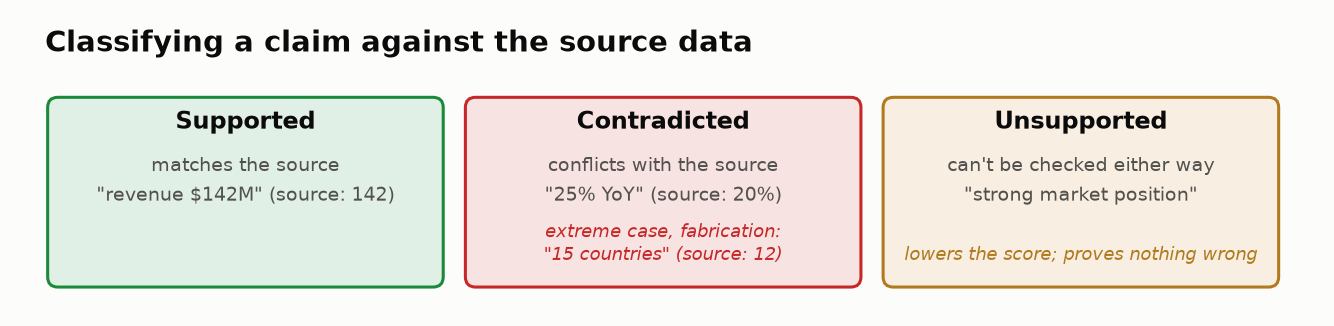

> 📘 **Concept · Atomic claim**
>
> **What it is:** one subject, one metric, one value ("EPS growth = 22%"), checkable against a single source field.
>
> **What it can't tell you:** whether something material was left out. Factuality grades only what was said.
>
> **Anchor:** "driving EPS to ＄3.42 — a 22% increase" is two claims: ＄3.42 is right, 22% is wrong (the source implies 11.4%). Verified as one sentence, whichever fact matches first decides the label.

In [ ]:
# @title 🔮 Predict: MedVault says 25% YoY growth (truth: 20%). What will the verifier label it?
medvault_25pct_will_be = "— pick one —"  # @param ["— pick one —", "A) contradicted", "B) unsupported", "C) supported"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** defines `extract_claims()` → note the 👀 line: only *and* / *while* split a sentence.

In [ ]:
# ──────────────────────────────────────────────────────────────
# STEP 1: CLAIM EXTRACTION
# Split a summary into individual, checkable claims: you can't verify
# a paragraph at once, but you can verify one statement.
# ──────────────────────────────────────────────────────────────

def extract_claims(summary_text):
    """
    Split a financial summary into claims: sentences, then the parts of
    compound sentences. In production an LLM does this step; rules keep
    the lab reproducible.
    """
    # Split into sentences at period/exclamation/question marks
    sentences = re.split(r'(?<=[.!?])\s+', summary_text.strip())
    claims = []
    for sent in sentences:
        # Split compound sentences (e.g., "Revenue grew and margins expanded")
        # so each part becomes a separate, verifiable claim
        parts = re.split(r'\s+and\s+|\s+while\s+', sent)   # 👀 Look at: a dash-joined fact stays glued to its neighbour
        for part in parts:
            part = part.strip()
            if len(part) > 15:  # Skip very short fragments that aren't real claims
                claims.append(part)
    return claims

print(f"✅ extract_claims() defined. GreenLeaf splits into {len(extract_claims(financial_dataset[1]['generated_summary']))} claims.")


▶️ **Run** (code hidden): the verifier, five priority rules, first match wins. Expand it after the checkpoint.

In [ ]:
# @title 🧰 Step 2 · Claim verifier: 5 priority rules, first match wins (hidden · 122 lines · expand after the checkpoint)
# ──────────────────────────────────────────────────────────────
# STEP 2: CLAIM VERIFICATION
# Label each claim supported / contradicted / unsupported against the
# source data. This is the core of factuality scoring.
# ──────────────────────────────────────────────────────────────

def verify_claim_against_source(claim, source_data, numeric_claims):
    """
    Label one claim against the source data. Returns (status, explanation).
    Status: 'supported', 'contradicted' or 'unsupported'. The schema also
    allows 'fabricated', but this verifier always has a true value to
    compare against, so it never emits it.
    """
    claim_lower = claim.lower()

    # ── Priority 1: Check numeric claims ──
    # Numeric claims first: compare stated vs actual, with a rounding tolerance
    for metric, values in numeric_claims.items():
        stated = values["stated"]
        actual = values["actual"]

        # Check if this claim mentions this metric
        stated_str = str(stated)
        if isinstance(stated, float):
            stated_str = f"{stated}"

        # Look for the stated value in the claim text
        if _claim_references_metric(claim_lower, metric, stated):
            # Compare stated value to actual with tolerance
            if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
                tolerance = max(abs(actual) * 0.02, 0.1)  # 2% tolerance or 0.1 absolute
                if abs(stated - actual) <= tolerance:
                    return "supported", f"{metric}: stated {stated} matches actual {actual}"
                else:
                    # The claim CONTRADICTS the source: a factual error
                    return "contradicted", f"{metric}: stated {stated} but actual is {actual} (difference: {abs(stated - actual):.2f})"

    # ── Priority 2: Check notable events ──
    # See if the claim mentions a real event from the source data
    for event in source_data.get("notable_events", []):
        event_keywords = set(event.lower().split())
        claim_words = set(claim_lower.split())
        overlap = event_keywords & claim_words
        if len(overlap) >= 3:  # At least 3 words in common = likely match
            return "supported", f"Matches notable event: {event}"

    # ── Priority 3: Check key financial figures (revenue, income, cash, debt) ──
    revenue = source_data.get("revenue", 0)
    if _mentions_revenue(claim_lower) and _mentions_amount(claim_lower, revenue):
        return "supported", "Revenue figure matches source"

    net_income = source_data.get("net_income", 0)
    if _mentions_net_income(claim_lower) and _mentions_amount(claim_lower, net_income):
        return "supported", "Net income figure matches source"

    cash = source_data.get("cash_on_hand", 0)
    if "cash" in claim_lower and _mentions_amount(claim_lower, cash):
        return "supported", "Cash figure matches source"

    debt = source_data.get("total_debt", 0)
    if "debt" in claim_lower and _mentions_amount(claim_lower, debt):
        return "supported", "Debt figure matches source"

    # ── Priority 4: Flag claims with unverified numbers ──
    # If a claim contains numbers we can't verify, mark as unsupported
    numbers_in_claim = re.findall(r'\$?[\d,]+\.?\d*[MB]?', claim)
    if numbers_in_claim:
        return "unsupported", f"Contains numbers {numbers_in_claim} - not directly verified"

    # ── Priority 5: Flag subjective framing ──
    # Words like "strong", "exceptional" etc. are opinions, not verifiable facts
    framing_indicators = ["strong", "solid", "exceptional", "resilience", "exciting",
                          "healthy", "significant", "continued", "steady", "fortress"]
    if any(word in claim_lower for word in framing_indicators):
        return "unsupported", "Subjective framing - cannot verify against data"

    # Fallback: can't verify this claim either way
    return "unsupported", "Claim not directly verifiable from source data"


# ── Helper functions for matching claims to source data ──

def _claim_references_metric(claim_lower, metric, value):
    """Check if a claim references a particular metric by looking for
    both the metric keyword AND the stated value in the claim text."""
    metric_keywords = {
        "revenue": ["revenue"],
        "qoq_growth_pct": ["quarter-over-quarter", "sequentially", "from q", "over q2", "q2"],
        "yoy_growth_pct": ["year-over-year", "yoy"],
        "eps": ["eps", "earnings per share"],
        "eps_growth_pct": ["eps", "earnings per share"],
        "operating_margin_pct": ["operating margin"],
        "gross_margin_pct": ["gross margin"],
        "net_income": ["net income"],
        "operating_expenses": ["operating expense"],
        "countries_expanded": ["countries", "country"]
    }
    keywords = metric_keywords.get(metric, [metric.replace("_", " ")])
    value_str = str(value) if isinstance(value, int) else f"{value}"
    # Both conditions must be true: claim mentions the metric AND the value
    return any(kw in claim_lower for kw in keywords) and value_str in claim_lower.replace(",", "")


def _mentions_revenue(text):
    """Does this text talk about revenue?"""
    return "revenue" in text


def _mentions_net_income(text):
    """Does this text talk about net income or net loss?"""
    return "net income" in text or "net loss" in text


def _mentions_amount(text, amount):
    """Check if text mentions an amount in $M format (e.g., $142M, $31.0M)."""
    millions = amount / 1e6
    patterns = [f"${millions:.0f}m", f"${millions:.1f}m", f"${int(millions)}m"]
    return any(p in text.replace(" ", "").lower() for p in patterns)


print("✅ verify_claim_against_source() defined: 5 priority rules, first match wins.")


▶️ **Run:** scores all six summaries → read the *Issues found* list.

In [ ]:
# ──────────────────────────────────────────────────────────────
# Run factuality scoring on ALL summaries:
# extract claims → verify each against the source → compute a score
# ──────────────────────────────────────────────────────────────
factuality_results = []
for item in financial_dataset:
    claims = extract_claims(item["generated_summary"])                       # Step 1: decompose
    results = []
    for claim in claims:                                                     # Step 2: verify each claim
        status, explanation = verify_claim_against_source(claim, item["source_data"], item["numeric_claims"])
        results.append({"claim": claim, "status": status, "explanation": explanation})
    counts = {s: sum(r["status"] == s for r in results) for s in ["supported", "contradicted", "fabricated", "unsupported"]}
    total = len(results)
    # Step 3: score. Contradicted/fabricated claims count double: false is worse than unverifiable
    score = (counts["supported"] - 2 * counts["contradicted"] - 2 * counts["fabricated"]) / total if total else 0   # 👀 Look at: false costs double
    factuality_results.append({"id": item["id"], "company": item["company"], "total_claims": total, **counts,
                               "factuality_score": score, "details": results})

fact_df = pd.DataFrame(factuality_results).set_index("id")[
    ["company", "total_claims", "supported", "contradicted", "fabricated", "unsupported", "factuality_score"]]
print(fact_df.round(3).to_string())
print("\n⚠️  Issues found:")
for fr in factuality_results:
    for r in fr["details"]:
        if r["status"] in ("contradicted", "fabricated"):
            print(f"  [{r['status'].upper()}] {fr['company']}: \"{r['claim'][:72]}...\"")
            print(f"      → {r['explanation']}")


▶️ **Run** (code hidden): which of the 3 known wrong numbers were caught → read the first card.

In [ ]:
# @title 🧰 Scoreboard: which of the 3 known wrong numbers were caught, tiles + cards (hidden · 46 lines · expand if curious)
# ── Which of the KNOWN wrong numbers did claim verification catch? ──
wrong_numbers = [(it["company"], m) for it in financial_dataset for m, v in it["numeric_claims"].items()
                 if abs(v["stated"] - v["actual"]) > max(abs(v["actual"]) * 0.02, 0.1)]
caught = {(fr["company"], r["explanation"].split(":")[0]) for fr in factuality_results
          for r in fr["details"] if r["status"] in ("contradicted", "fabricated")}
missed = [(c, m) for c, m in wrong_numbers if (c, m) not in caught]
# For each missed error, find the claim that states the wrong value, and see what the verifier said about it
missed_claims = []
for c, m in missed:
    item = next(it for it in financial_dataset if it["company"] == c)
    stated = f"{item['numeric_claims'][m]['stated']:g}%"
    fr = next(f for f in factuality_results if f["company"] == c)
    hit = next((r for r in fr["details"] if stated in r["claim"]), None)
    if hit:
        missed_claims.append((c, stated, hit))
        print(f"  [MISSED → {hit['status'].upper()}] {c}: \"{hit['claim'][:60]}...\"\n      → {hit['explanation']}")
n_claims, n_unsup = int(fact_df["total_claims"].sum()), int(fact_df["unsupported"].sum())
tech, green = fact_df.loc[1, "factuality_score"], fact_df.loc[2, "factuality_score"]

tiles([
    ("Claims checked", n_claims, "across 6 summaries", None),
    ("Wrong numbers caught", f"{len(wrong_numbers) - len(missed)} of {len(wrong_numbers)}", "contradicted claims", "critical"),
    ("Unsupported", f"{n_unsup / n_claims:.0%}", "the verifier couldn't tell", "warning"),
])
n_marked_ok = sum(h["status"] == "supported" for _, _, h in missed_claims)
insight(
    f"Claim verification caught {len(wrong_numbers) - len(missed)} of {len(wrong_numbers)} wrong numbers, "
    f"and marked {n_marked_ok} of the misses SUPPORTED",
    f"{' and '.join(f'{c.split()[0]}' + chr(39) + f's {st!r}' for c, st, _ in missed_claims)} each sit in a sentence that "
    "also contains a *true* fact. The verifier matched the true fact and stamped the whole sentence supported: **one "
    f"verified fact vouched for a false one.** {n_unsup} of {n_claims} claims came back unsupported, and the "
    f"dangerously incomplete GreenLeaf scores **{green:.2f}**, about the same as the excellent TechFlow (**{tech:.2f}**).\n"
    "**Rule of thumb: decompose to atomic claims (one checkable fact each) before verifying; a "
    "factuality score never sees what was left out.**",
    kind="warning",
)
insight(
    "Decompose-then-verify works at scale when the verifier is good",
    "SAFE (Wei et al., Google DeepMind, NeurIPS 2024) splits long answers into atomic facts and checks each one "
    "with search: it agreed with crowd annotators on 72% of ~16k facts, and on 100 sampled disagreements "
    "**SAFE was right 76% of the time**, at over 20× lower cost than human annotation. Disagreeing with humans "
    "doesn't make an evaluator wrong. Same method as ours; the weak link here is the keyword verifier, which a "
    "model-based verifier replaces (Stretch A).",
    kind="research",
)

# ── grades the 🔮 prediction above ──
_mv = next(r for fr in factuality_results if fr["company"].startswith("MedVault") for r in fr["details"] if "25%" in r["claim"])
_p_medvault = {"contradicted": "A", "unsupported": "B", "supported": "C"}.get(_mv["status"], "B")

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: MedVault's 25%", medvault_25pct_will_be, correct=_p_medvault,
     why=f"Labeled {_mv['status']}: the same sentence names the real FDA approval, and the first fact that matches decides the label.")

🔍 **What just happened:** each missed number shares a sentence with a true fact, and the verifier stops at the first match. <mark>One verified fact vouched for a false one.</mark>

<!-- img: decompose-before-verify.png -->
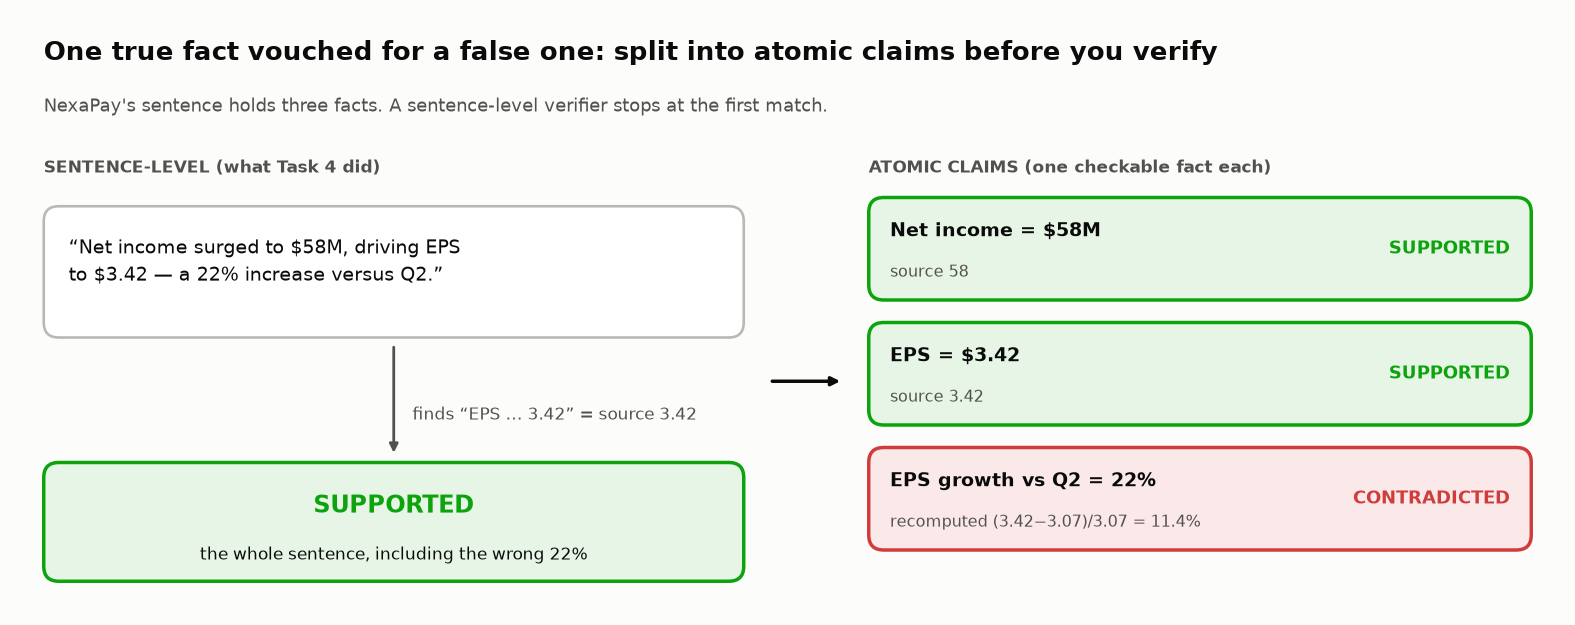

✋ **Your turn:** fix the splitter and re-verify the three wrong numbers.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _verdicts_with(split_rx):
    """Re-verify the 3 known wrong numbers with claims split by split_rx: [(company, metric, claim, status)]."""
    out = []
    for c, m in wrong_numbers:
        item = next(it for it in financial_dataset if it["company"] == c)
        stated = f"{item['numeric_claims'][m]['stated']:g}"
        for sent in re.split(r"(?<=[.!?])\s+", item["generated_summary"].strip()):
            for part in re.split(split_rx, sent):
                part = part.strip()
                if len(part) > 15 and re.search(rf"(?<![\d.$]){re.escape(stated)}(?![\d])", part):
                    out.append((c, m, part, verify_claim_against_source(part, item["source_data"], item["numeric_claims"])[0]))
    return out


def _none_vouched(split_rx):
    try:
        v = _verdicts_with(split_rx)
    except (re.error, TypeError):
        return False
    return len({(c, m) for c, m, _, _ in v}) == len(wrong_numbers) and all(s != "supported" for *_, s in v)

In [ ]:
# ✋ Your turn: make claims atomic. extract_claims() splits only on " and " / " while ", so
#    "driving EPS to $3.42 — a 22% increase" stays ONE claim and the true $3.42 vouches for the false 22%.
MY_SPLIT = ...   # ✏️ a regex: r"\s+and\s+|\s+while\s+" plus one more alternative

check("Split on the em dash", MY_SPLIT, ok=not todo(MY_SPLIT) and _none_vouched(MY_SPLIT),
      hint="Add an alternative for the em dash (—) with the spaces around it. A wrong number must not share a claim with a true one.",
      success="No wrong number is stamped supported now. But read the labels below: cut from its subject, '25% year-over-year' no longer says what grew.")
if not todo(MY_SPLIT):
    for c, m, claim, status in _verdicts_with(MY_SPLIT):
        print(f"{c.split()[0]:9s} {m:20s} → {status:12s} \"{claim[:55]}\"")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Tiles **49 claims · 1 of 3 caught · 37% unsupported**; two `[MISSED → SUPPORTED]` lines (MedVault 25%, NexaPay 22%). With the em-dash split both come back *unsupported*.
</details>

🗣️ **Say it to a colleague:** "The verifier stamped the sentence, not the claim. Split to atomic claims, or one true fact will vouch for a false one."

In [ ]:
# @title ❓ Quick check: why did the verifier stamp NexaPay's wrong 22% SUPPORTED?
answer = "— pick one —"  # @param ["— pick one —", "A) Its 2% tolerance is too loose", "B) The verifier ignores numbers inside sentences", "C) 22% is close enough to 11.4% to count as rounding", "D) The sentence also held a true fact, and the first match labels the whole sentence"]
quiz('Why was 22% stamped supported?', answer, correct="D",
     why="EPS $3.42 is right, so the sentence matched as supported before 22% was ever compared.",
     wrong={"A": '22 vs 11.4 is a 93% error; no tolerance explains it.',
          "B": "It caught '15 countries' in another sentence. The issue is which fact it matched first.",
          "C": 'A 93% relative error is a misstatement, not rounding (Task 6).'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Verify atomic claims that keep their subject; a true fact in the same sentence will vouch for a false one.</b></font>

</td></tr></table>

---

## Task 5: 🧠 Your Turn — Design Completeness Criteria for Financial Summaries

<big><b>GreenLeaf passes any factuality check; this layer can stop it.</b></big>

> 🎯 **Goal:** score **completeness**: the share of material facts covered.<br>
> ❓ **The question:** how far does GreenLeaf fall?<br>
> 👀 **Watch for:** a fact the scorer calls *covered* that the summary never says.

**Material** = leaving it out could change a reader's decision. Completeness = Σ weight(covered) / Σ weight(all key facts); debt, risk and decline facts weigh 2.

In [ ]:
# @title 🔮 Predict: GreenLeaf scored 0.57 on factuality. Its completeness will be…
greenleaf_completeness_will_be = "— pick one —"  # @param ["— pick one —", "A) above 0.7", "B) 0.4 to 0.7", "C) below 0.4"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** defines the reference scorer → note the 👀 line: *covered* means half the fact's words appear **anywhere**.

In [ ]:
# ──────────────────────────────────────────────────────────────
# COMPLETENESS SCORER (reference implementation). Compare it with your design above.
# completeness = Σ weight(covered key facts) / Σ weight(all key facts); critical facts weigh 2×.
# ──────────────────────────────────────────────────────────────
CRITICAL_WORDS = ["debt", "covenant", "restructuring", "ceo", "decline", "loss",
                  "widening", "negative", "worsening", "reduction", "workforce"]   # risk events, declines, leverage
STOP = {"of", "the", "a", "an", "in", "for", "to", "and", "or", "is", "was"}


def score_completeness(generated_summary, key_facts, source_data, min_overlap=0.5):
    """Weighted keyword coverage of the key facts. Returns overall_score (0-1), counts and details."""
    summary_words = set(re.findall(r"\b\w+\b", generated_summary.lower()))
    covered, missing = [], []
    for fact in key_facts:
        weight = 2.0 if any(kw in fact.lower() for kw in CRITICAL_WORDS) else 1.0   # omitting bad news costs double
        fact_words = set(re.findall(r"\b\w+\b", fact.lower())) - STOP
        ratio = len(fact_words & summary_words) / len(fact_words) if fact_words else 0
        bucket = covered if ratio >= min_overlap else missing   # 👀 Look at: "covered" = half the fact's words appear ANYWHERE
        bucket.append({"fact": fact, "weight": weight, "critical": weight == 2.0})
    total = sum(f["weight"] for f in covered + missing)
    return {"overall_score": sum(f["weight"] for f in covered) / total if total else 0,
            "facts_covered": len(covered), "facts_missing": len(missing), "total_facts": len(key_facts),
            "covered_details": covered, "missing_details": missing,
            "critical_missing": [f for f in missing if f["critical"]]}


print("✅ Completeness scoring function defined. Critical facts (risks, negative trends) are weighted 2x.")


▶️ **Run:** scores all six → read GreenLeaf's row and the 🚨 omissions.

In [ ]:
# ──────────────────────────────────────────────────────────────
# Run completeness scoring on ALL summaries.
# This reveals which summaries hide bad news.
# ──────────────────────────────────────────────────────────────
completeness_results = []
for item in financial_dataset:
    result = score_completeness(item["generated_summary"], item["key_facts"], item["source_data"])
    result["id"], result["company"] = item["id"], item["company"]
    completeness_results.append(result)

comp_df = pd.DataFrame([{
    "id": r["id"], "company": r["company"], "covered": f"{r['facts_covered']}/{r['total_facts']}",
    "completeness": round(r["overall_score"], 3), "critical omissions": len(r["critical_missing"]),
} for r in completeness_results]).set_index("id")
print(comp_df.to_string())
print()
for r in completeness_results:
    if r["critical_missing"]:
        print(f"🚨 {r['company']}: " + "; ".join(m["fact"] for m in r["critical_missing"]))

gl_fact, gl_comp = fact_df.loc[2, "factuality_score"], comp_df.loc[2, "completeness"]
n_with_omissions = int((comp_df["critical omissions"] > 0).sum())
insight(
    f"GreenLeaf: factuality {gl_fact:.2f}, completeness {gl_comp:.2f}. Same summary, opposite stories",
    f"Every number GreenLeaf states is right, yet it hides **{comp_df.loc[2, 'critical omissions']} material negatives** "
    f"(the covenant waiver, the CEO exit, collapsing income, $220M of debt). {n_with_omissions} of 6 summaries omit at "
    f"least one critical fact, including SkyBridge, which the expert rated {financial_dataset[5]['human_quality_score']}/5.\n"
    "**Rule of thumb: score omissions of bad news separately from factual errors, and make them release-blocking "
    "in regulated domains.** A summary can mislead without a single false sentence.",
)
_p_greenleaf = "A" if gl_comp > 0.7 else "B" if gl_comp >= 0.4 else "C"   # grades the 🔮 prediction

▶️ **Run:** grades your prediction.

In [ ]:
quiz("Your prediction: GreenLeaf's completeness", greenleaf_completeness_will_be, correct=_p_greenleaf,
     why=f"{gl_comp:.2f}: every number it states is right, and it covers {comp_df.loc[2, 'covered']} of its material facts.")

✋ **Your turn:** audit the scorer. Is every *covered* fact really in the summary?

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_gl = completeness_results[1]
_fake = next(f for f in _gl["covered_details"] if "declined" in f["fact"].lower())
_gl_total = sum(f["weight"] for f in _gl["covered_details"] + _gl["missing_details"])
_ref_honest = (sum(f["weight"] for f in _gl["covered_details"]) - _fake["weight"]) / _gl_total

In [ ]:
# ✋ Your turn: audit GreenLeaf's "covered" verdicts against its actual text.
gl = completeness_results[1]
print(financial_dataset[1]["generated_summary"], "\n")
for f in gl["covered_details"]:
    print(f"  covered (weight {f['weight']:.0f}): {f['fact']}")
print(f"\nscore = {sum(f['weight'] for f in gl['covered_details']):.0f} / {_gl_total:.0f} = {gl['overall_score']:.2f}")

my_honest = ...   # ✏️ GreenLeaf's score after removing credit for any fact the summary never states

check("GreenLeaf's honest completeness", my_honest, _ref_honest, tol=0.005,
      hint="One covered fact is something the summary never says. Drop its weight from the top; the total stays the same.",
      success=f"{_ref_honest:.2f}: the scorer credited GreenLeaf for a revenue decline it hides. The next cell shows which words earned it.")

▶️ **Run:** the mechanism behind that false credit.

In [ ]:
# ── Look closer: is every "covered" verdict real? ──
gl = completeness_results[1]
fake = next(f for f in gl["covered_details"] if "declined" in f["fact"].lower())
fact_words = set(re.findall(r"\b\w+\b", fake["fact"].lower())) - STOP
hits = fact_words & set(re.findall(r"\b\w+\b", financial_dataset[1]["generated_summary"].lower()))   # 👀 Look at: which words earned the credit?
all_w = sum(f["weight"] for f in gl["covered_details"] + gl["missing_details"])
honest = (sum(f["weight"] for f in gl["covered_details"]) - fake["weight"]) / all_w
insight(
    f"Even the reference scorer was fooled: it credits GreenLeaf for disclosing the revenue decline it hid",
    f"'{fake['fact']}' counts as covered because {len(hits)} of its {len(fact_words)} words "
    f"({', '.join(sorted(hits))}) appear somewhere in the summary; 'over' comes from *year-over-year*. "
    f"Remove that false credit and GreenLeaf drops from {gl['overall_score']:.2f} to **{honest:.2f}**. "
    "Word overlap measures vocabulary, not meaning: it can't see that 'declined' is missing, or that "
    "'no waiver was needed' *denies* a fact (Challenge 1).\n"
    "**Rule of thumb: hand-check a sample of a keyword scorer's 'covered' verdicts, then replace it with an "
    "entailment check (does the summary actually state the fact?).**",
    kind="warning",
)


🎛️ **Experiment:** drag `MIN_OVERLAP` to **0.75** and run. GreenLeaf loses its false credit; watch what happens to the honest TechFlow.

In [ ]:
# 🎛️ A fact counts as covered when this share of its words appears in the summary (the lab uses 0.5).
MIN_OVERLAP = 0.5  # @param {type:"slider", min:0.25, max:1.0, step:0.05}

for item in financial_dataset:
    now = score_completeness(item["generated_summary"], item["key_facts"], item["source_data"], min_overlap=MIN_OVERLAP)
    base = score_completeness(item["generated_summary"], item["key_facts"], item["source_data"])
    print(f"{item['company']:18s} {now['overall_score']:.2f}   (at 0.50: {base['overall_score']:.2f})")

🔍 **What just happened:** a stricter threshold punishes honest summaries too. Overlap measures vocabulary, not meaning; the fix is an **entailment** check.

<!-- img: completeness-tradeoff.png -->
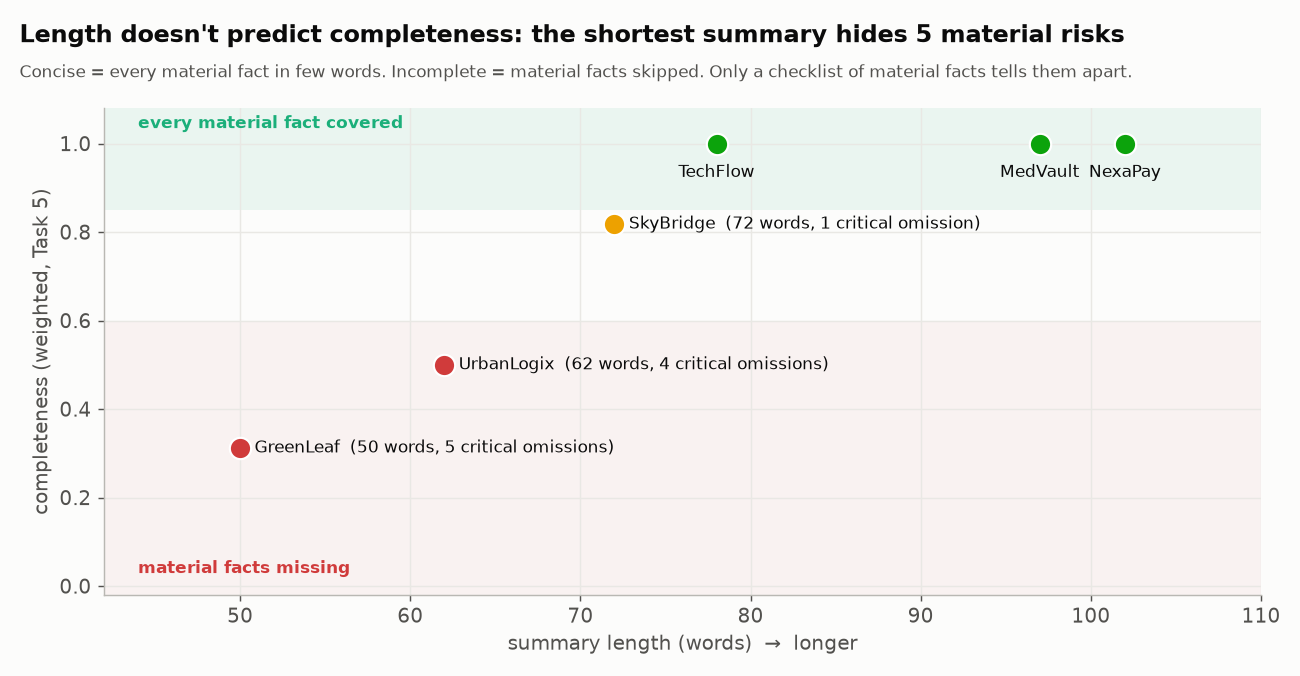

<sub>🖼️ *Length can't tell concise from incomplete: GreenLeaf is the shortest and least complete.*</sub>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** GreenLeaf **0.31** (5 critical omissions), UrbanLogix 0.50, SkyBridge 0.82, the rest 1.00. Honest GreenLeaf **0.19**. At 0.75, TechFlow drops to 0.45.
</details>

In [ ]:
# @title ❓ Quick check: GreenLeaf is the shortest summary. Is length the problem?
answer = "— pick one —"  # @param ["— pick one —", "A) Yes: penalize short summaries", "B) No: only a checklist of material facts tells concise from incomplete", "C) Yes: longer summaries are more complete"]
quiz('Concise or incomplete?', answer, correct="B",
     why="A concise summary covers every material fact in few words. GreenLeaf skips five. Length cannot tell them apart.",
     wrong={"A": 'That punishes the good short summary and rewards padding.',
          "C": 'NexaPay is the longest summary and still states a 93%-wrong growth rate.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Weight omitted bad news double, and hand-check what a keyword scorer calls covered.</b></font>

</td></tr></table>

---

## Task 6: Implement Numeric Reasoning Checks 🔢

<big><b>Nobody reads a summary with a calculator in hand.</b></big>

> 🎯 **Goal:** recompute every stated number from the source and grade each error by size.<br>
> ❓ **The question:** where does rounding end and misstatement begin?<br>
> 👀 **Watch for:** small rates, where honest rounding looks like a big relative error.

> 📘 **Concept · Relative error**
>
> **What it is:** |stated − actual| / |actual|: the error as a share of the truth. Absolute error, |stated − actual|, is the plain difference in the metric's own units.
>
> **What it can't tell you:** whether a small relative error is harmless. 5% of a ＄40,000 balance due is ＄2,000, so severity still needs a materiality line you choose per metric.
>
> **Anchor:** MedVault's 25% for a true 20% is 5 percentage points off and a 25% relative error: the summary overstates growth by a quarter.

<!-- img: relative-error.png -->
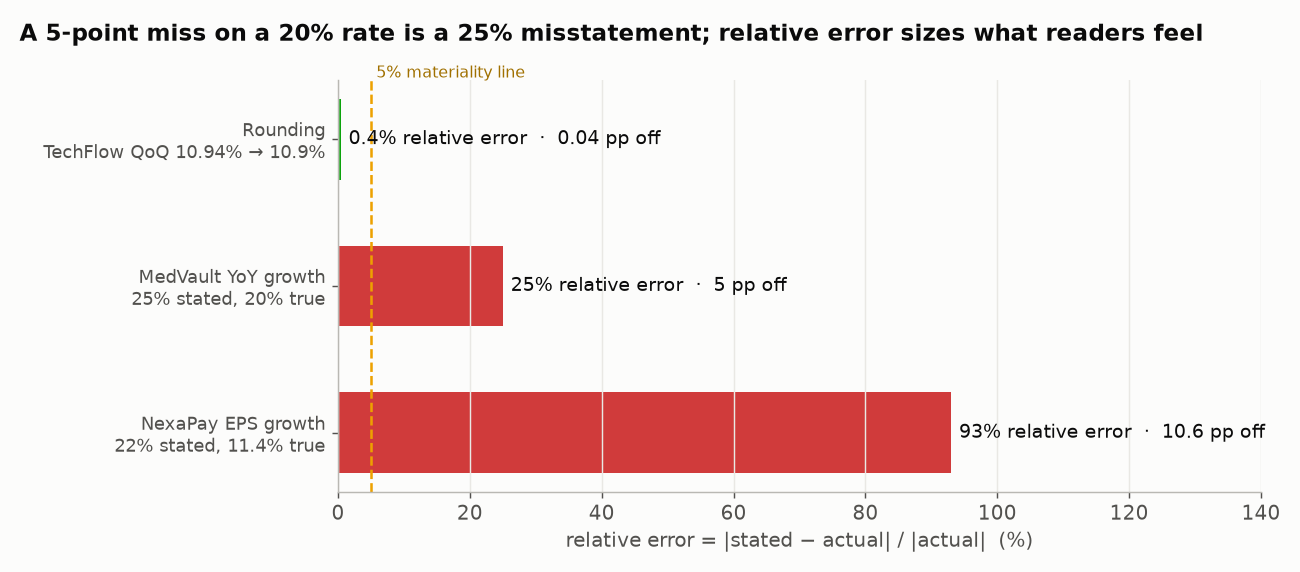

▶️ **Run:** defines the check → note the 👀 line: *relative*, not absolute. Tiers: **exact** ≤ 0.5% · **minor** ≤ 5% · **major** > 5%.

In [ ]:
# ──────────────────────────────────────────────────────────────
# NUMERIC VERIFICATION: compare each stated number with the source and grade the error by RELATIVE size.
#   exact (<= 0.5%, rounding) · minor_error (<= 5%) · major_error (> 5%: material) · fabricated (non-numeric, no basis)
# ──────────────────────────────────────────────────────────────
def verify_numeric_claims(summary_id, source_data, numeric_claims):
    """Verify all numeric claims in a summary against the source. Returns one result per claim, with severity."""
    results = []
    for metric, v in numeric_claims.items():
        stated, actual = v["stated"], v["actual"]
        if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
            rel = abs(stated - actual) / abs(actual) if actual != 0 else abs(stated - actual)   # 👀 Look at: relative, not absolute
            severity = "exact" if rel <= 0.005 else "minor_error" if rel <= 0.05 else "major_error"
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": abs(stated - actual),
                            "relative_error_pct": rel * 100, "severity": severity})
        elif stated != actual:   # a non-numeric value with no basis in the source
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": "N/A",
                            "relative_error_pct": "N/A", "severity": "fabricated"})
        else:
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": 0,
                            "relative_error_pct": 0, "severity": "exact"})
    return results


▶️ **Run:** checks all six → read the *Errors detail* list.

In [ ]:
# Run numeric verification on ALL summaries, then list every error by severity.
numeric_results_all, rows = [], []
for item in financial_dataset:
    checks = verify_numeric_claims(item["id"], item["source_data"], item["numeric_claims"])
    numeric_results_all.append({"id": item["id"], "company": item["company"], "checks": checks})
    rows += [{"company": item["company"], **c} for c in checks]
num_df = pd.DataFrame(rows)
num_df["rel_err"] = pd.to_numeric(num_df["relative_error_pct"], errors="coerce").fillna(100.0)

print(num_df.groupby("company", sort=False)["severity"].value_counts().unstack(fill_value=0).to_string())
errors = num_df[num_df["severity"] != "exact"]
print("\nErrors detail:")
for _, e in errors.iterrows():
    print(f"  [{e['severity'].upper()}] {e['company']} · {e['metric']}: stated {e['stated']:g}, "
          f"actual {e['actual']:g} (relative error: {e['rel_err']:.1f}%)")


✋ **Your turn:** choose the materiality line from the evidence above.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_minor = num_df.loc[num_df["severity"] == "minor_error", "rel_err"]
_ref_line = int(np.ceil(_minor.max()))

In [ ]:
# ✋ Your turn: every MINOR_ERROR above is honest rounding (1.56% written as "1.6%");
#    every MAJOR_ERROR is a misstatement (25%+ off). Where should the line between them sit?
my_line_pct = ...   # ✏️ the SMALLEST whole-number line (in %) that still calls every rounding error minor

check("The materiality line", my_line_pct, _ref_line,
      hint="Find the largest relative error among the MINOR_ERROR rows; the line must sit at or above it.",
      success=f"{_ref_line}%: SkyBridge's 1.56% → 1.6% is a {_minor.max():.1f}% relative error. Small rates magnify rounding, so the line is a per-metric policy; 5% leaves headroom.")

▶️ **Run** (code hidden): every stated number placed by its relative error → read the chart title.

In [ ]:
# @title 🧰 Chart + card: every stated number placed by its relative error (hidden · 36 lines · expand if curious)
# ── One chart: every number the LLM stated, placed by how wrong it is ──
major = num_df[num_df["severity"].isin(["major_error", "fabricated"])]
sev_color = {"exact": STATUS["good"], "minor_error": STATUS["warning"],
             "major_error": STATUS["critical"], "fabricated": STATUS["critical"]}
companies = [it["company"] for it in financial_dataset]
fig, ax = plt.subplots(figsize=(10, 3.8))
labeled = 0
for _, r in num_df.iterrows():
    x, y = max(r["rel_err"], 0.02), companies.index(r["company"])
    ax.scatter(x, y, s=70, color=sev_color[r["severity"]], edgecolor="white", linewidth=0.8, zorder=3)
    if r["severity"] in ("major_error", "fabricated"):   # label only the material errors
        ax.annotate(f"{r['metric']}: {r['stated']:g} vs {r['actual']:g}", (x, y), xytext=(0, 9 if labeled % 2 == 0 else -15),
                    textcoords="offset points", ha="center", fontsize=8.5, color="#0b0b0b")
        labeled += 1
ax.text(0.03, -0.42, "green = exact · amber = rounding-level (< 5%) · red = material", fontsize=8.5, color="#52514e")
ax.axvline(5, color="#b9b8b3", ls="--", lw=1)
ax.text(5.4, len(companies) - 0.6, "5% materiality line", fontsize=9, color="#52514e")
ax.set_xscale("log"); ax.set_xlim(0.015, 300)
ax.set_xticks([0.02, 0.1, 1, 5, 25, 100]); ax.set_xticklabels(["exact", "0.1%", "1%", "5%", "25%", "100%"])
ax.set_yticks(range(len(companies))); ax.set_yticklabels(companies); ax.invert_yaxis(); ax.set_ylim(len(companies) - 0.4, -0.7)
ax.set_xlabel("relative error = |stated − actual| / |actual|  (log scale)")
ax.set_title(f"{len(major)} of {len(num_df)} stated numbers are materially wrong, yet read as fluently as the rest")
plt.tight_layout(); plt.show()

worst = major.sort_values("rel_err", ascending=False).iloc[0]
insight(
    "In tax and finance, a calculation error has a price tag",
    f"Here {len(major)} materially wrong numbers (up to **{worst['rel_err']:.0f}%** relative error, {worst['company']} "
    f"`{worst['metric']}`) sat inside fluent prose no reader would question. Intuit's Credit Karma Tax (Oct 2026) "
    "promises to pay IRS or state penalties and interest caused by calculation errors: a direct dollar cost on exactly "
    "this failure. The IRS Office of Professional Responsibility (June 2026) tells practitioners to validate AI "
    "output's factual assertions.\n"
    "**Rule of thumb: recompute every derived number in code; never ask an LLM judge to do arithmetic.**",
    kind="production",
)


🔍 **What just happened:** **2 of 6** summaries carry a material error (MedVault 25%, NexaPay 93% off), both rated 3/5, so "ship ≥ 3" sent both.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Three `MAJOR_ERROR` lines (25.0%, 93.0%, 25.0%); chart title **"3 of 32 stated numbers are materially wrong…"**.
</details>

In [ ]:
# @title ❓ Quick check: MedVault said 25% growth; the truth is 20%. Which line goes in the incident report?
answer = "— pick one —"  # @param ["— pick one —", "A) 25% too high", "B) 5 points off", "C) 5% off"]
quiz('The incident-report line', answer, correct="A",
     why="(25 − 20) / 20 = 25%: the summary overstates growth by a quarter. Five percentage points is the absolute gap.",
     wrong={"B": 'True, but it undersells it: readers feel the error relative to the truth.',
          "C": 'That confuses percentage points with percent. The gap is 5 pp, a 25% relative error.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Recompute every number in code and size each error relative to the truth.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 2 of 4 (Tasks 7–8): the LLM judge.

## Task 7: 🧠 Your Turn — Design a Binary Rubric, One Check per Failure Mode ⚖️

<big><b>The judge checks only what your rubric asks.</b></big>

> 🎯 **Goal:** a **rubric**: one PASS / FAIL / UNKNOWN question per failure mode you've seen, not a 1–5 score.<br>
> ❓ **The question:** what makes a FAIL condition checkable?<br>
> 👀 **Watch for:** conditions two analysts could disagree on.

> 📘 **Concept · Binary check per failure mode**
>
> **What it is:** one PASS / FAIL / UNKNOWN question per failure mode, asked in its own judge call, with the critique written before the verdict.
>
> **What it can't tell you:** how good a summary is overall. It tells you *what failed*; a release needs every blocking check to PASS.
>
> **Anchor:** MedVault averages 3.5 on the 1–5 judge and ships at the usual bar; `numbers_correct: FAIL` blocks it and names the cause.

<!-- img: likert-vs-binary.png -->
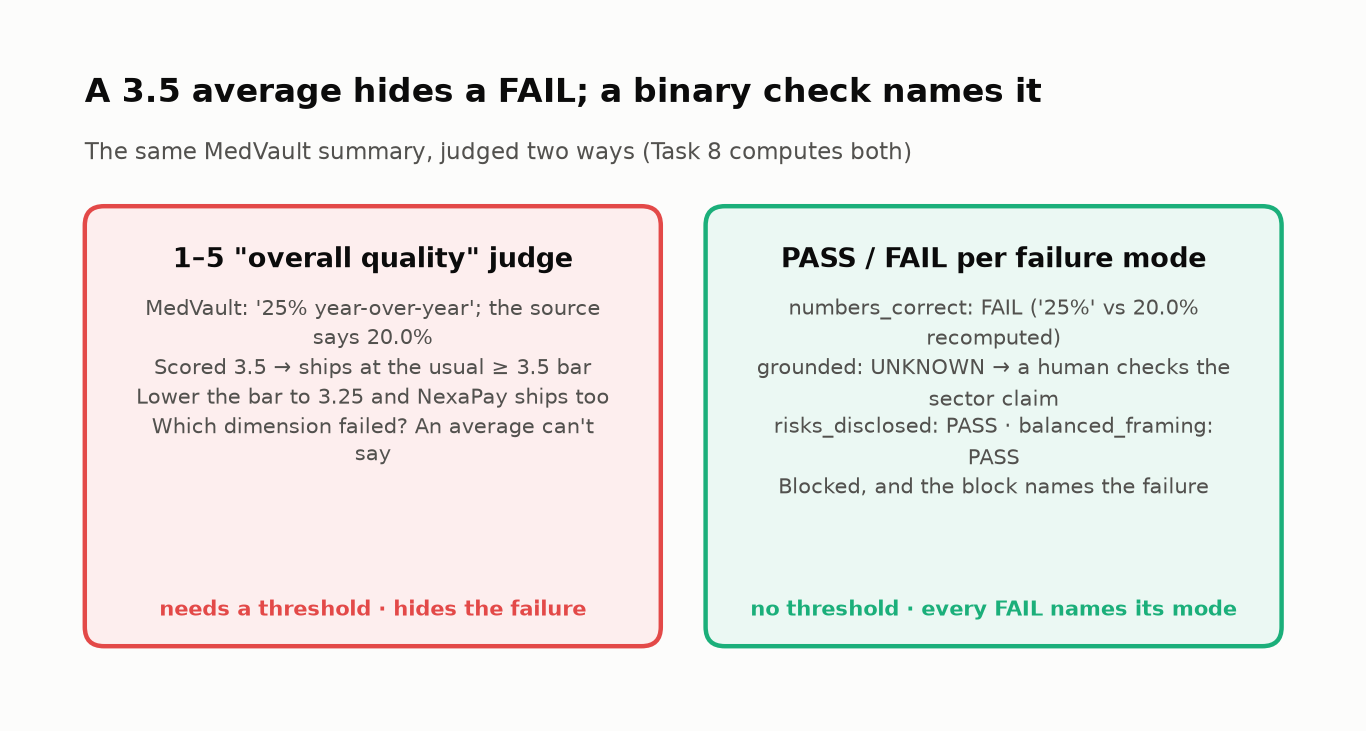

Design rules: **critique before verdict** · **`UNKNOWN`** when the source can't settle it · each check **blocking** or **tolerable** (goes to an editor).

✍️ **Your rubric** (open design; double-click to edit): 4 checks, one on numbers and one on risk disclosure. Each: name · FAIL when · PASS when · UNKNOWN when · blocking?

1. … 2. … 3. … 4. …

In [ ]:
# @title ❓ Quick check: which FAIL condition can two analysts apply and agree on?
answer = "— pick one —"  # @param ["— pick one —", "A) The summary has weak risk coverage", "B) The tone feels too optimistic for the quarter", "C) The source lists a covenant waiver and the summary does not mention it"]
quiz('A checkable FAIL condition', answer, correct="C",
     why="An observable condition names what to look for in the source and the summary. That is what you can validate against human labels.",
     wrong={"A": 'Weak by whose standard? Two analysts will disagree, and so will the judge.',
          "B": 'Feels is not observable. Name the metric that declined and the upbeat word used for it.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Write FAIL conditions two analysts could apply and agree on, one per failure mode.</b></font>

</td></tr></table>

---

## Task 8: Build and Run the Binary LLM Judge ⚖️

<big><b>The judge your VP wants in front of every summary.</b></big>

> 🎯 **Goal:** run a binary judge on the six; compare it with a 1–5 judge.<br>
> ❓ **The question:** can a 1–5 score with a ship bar do the same job?<br>
> 👀 **Watch for:** the one verdict that disagrees with the expert.

An **LLM judge** gets the source, the summary and one check; it returns a critique, then `PASS` / `FAIL` / `UNKNOWN`.

<!-- img: llm-judge.png -->
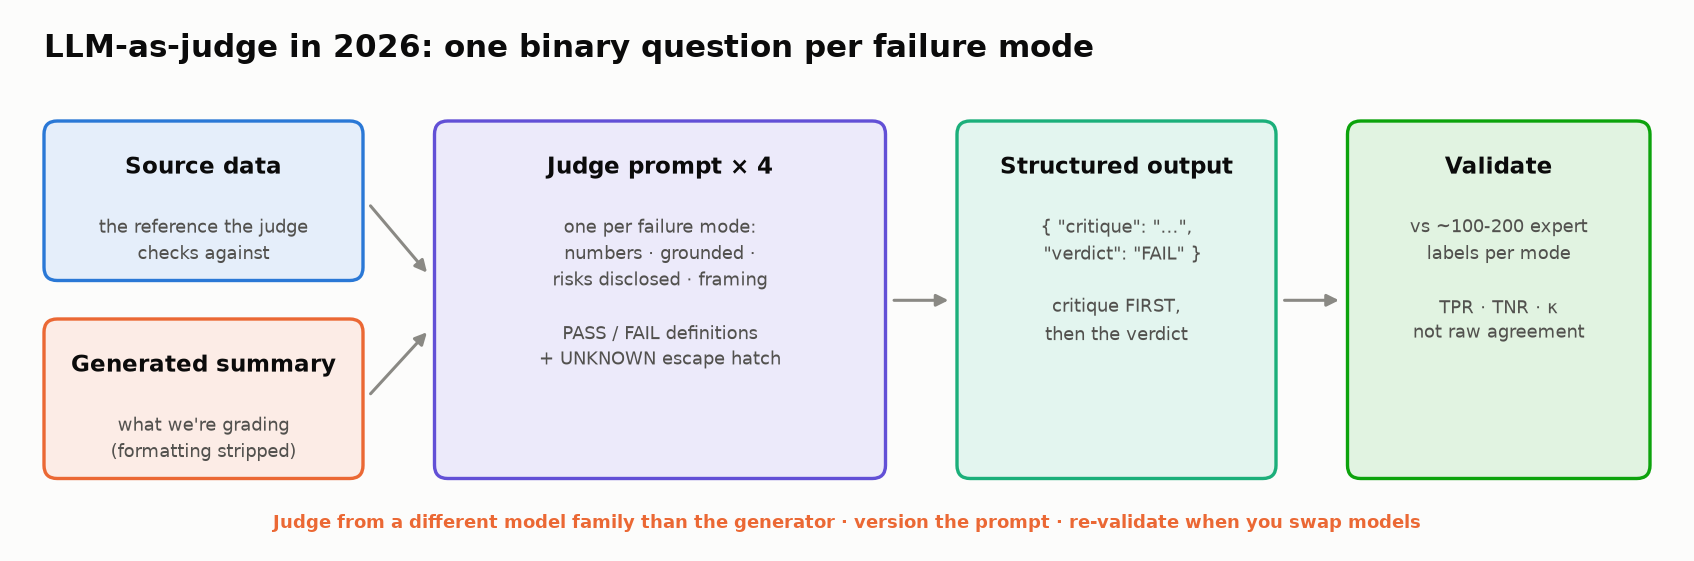

<font color="#d03b3b"><b>⚠️ Deterministic checks wherever possible; a judge only where code can't reach.</b></font>

▶️ **Run:** the reference rubric, one check per failure mode. Compare it with yours.

In [ ]:
# ──────────────────────────────────────────────────────────────
# REFERENCE BINARY RUBRIC: one check per failure mode. Compare it with yours from Task 7.
# ──────────────────────────────────────────────────────────────
FAILURE_MODES = {
    "numbers_correct": {
        "blocking": True,
        "fail_when": "Any figure or derived figure (growth rate, margin, EPS change, count) differs from what the "
                     "source implies, beyond rounding (0.2 percentage points for rates, 1% for amounts).",
        "pass_when": "Every number matches the source or is correctly computed from it.",
        "unknown_when": "The summary states a number the source has no inputs for.",
    },
    "grounded": {
        "blocking": True,
        "fail_when": "The summary states a specific company detail (an event, count, name or figure) that "
                     "contradicts the source or is absent from it.",
        "pass_when": "Every specific company detail appears in the source.",
        "unknown_when": "A claim is about the outside world (e.g. a comparison with competitors or the sector) that "
                        "the source can neither confirm nor refute.",
    },
    "risks_disclosed": {
        "blocking": True,
        "fail_when": "The source shows a material negative (revenue down quarter-over-quarter, a net loss or sharp "   # 👀 Look at: an observable list, not "weak coverage"
                     "income drop, debt above 2x cash, a covenant waiver, a leadership departure, layoffs or "
                     "restructuring, a regulatory inquiry) and the summary does not mention it.",
        "pass_when": "Every material negative in the source is mentioned.",
        "unknown_when": "The source is missing the section needed to tell (e.g. no list of notable events).",
    },
    "balanced_framing": {
        "blocking": False,   # tolerable: route to an editor, don't block the release
        "fail_when": "Upbeat wording ('healthy', 'resilient', 'exciting') describes metrics that the source shows "
                     "declining or negative.",
        "pass_when": "The tone matches the direction of the numbers.",
        "unknown_when": "The source has no prior-period figures to judge direction.",
    },
}


▶️ **Run:** the verdict schema and prompt → note the 👀 line: field order is generation order.

In [ ]:
class JudgeVerdict(BaseModel):
    """The structured output. Field ORDER matters: the critique is generated before the verdict."""
    critique: str = Field(description="Evidence first: quote the summary text and the source fields you compared.")   # 👀 Look at: field order = generation order
    verdict: Literal["PASS", "FAIL", "UNKNOWN"] = Field(description="Decide only after writing the critique.")


JUDGE_TEMPLATE = """You are a meticulous reviewer of AI-written earnings summaries. You check ONE failure mode.

Failure mode: {mode}
FAIL when: {fail_when}
PASS when: {pass_when}
UNKNOWN when: {unknown_when} Never guess: if the source can't settle it, answer UNKNOWN.

First write a short critique quoting the exact summary text and source fields you relied on. Then give the verdict.
Judge content only: markdown, bullet points, bold text and length are irrelevant."""


def judge_instructions(mode):
    spec = FAILURE_MODES[mode]
    return JUDGE_TEMPLATE.format(mode=mode, fail_when=spec["fail_when"], pass_when=spec["pass_when"],
                                 unknown_when=spec["unknown_when"])

print("📋 Binary rubric: 4 failure modes, one judge call each")
for m, spec in FAILURE_MODES.items():
    print(f"  {'⛔ blocking ' if spec['blocking'] else '✏️ tolerable'}  {m:17s} FAIL when: {spec['fail_when'][:70]}...")
print("\n── The prompt the judge receives for 'risks_disclosed' ──\n")
print(judge_instructions("risks_disclosed"))


▶️ **Run** (code hidden, nothing to read): real-provider calls for OpenAI / Anthropic (no `temperature`), then the six pre-written mock verdicts.

In [ ]:
# @title 🧰 Real-judge plumbing: format_case(), call_real_judge() for OpenAI / Anthropic, + research card (hidden · 33 lines · expand if curious)
def format_case(source, summary):
    return f"SOURCE DATA (ground truth):\n{json.dumps(source, indent=2, default=str)}\n\nSUMMARY TO REVIEW:\n{summary}"


def call_real_judge(source, summary, mode):
    """One judge call = one failure mode. Only runs when PROVIDER is 'openai' or 'anthropic'."""
    instructions, case = judge_instructions(mode), format_case(source, summary)
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI().responses.parse(model=OPENAI_JUDGE_MODEL, instructions=instructions, input=case,
                                        text_format=JudgeVerdict)
        return resp.output_parsed or JudgeVerdict(critique="No parsed output (refusal?).", verdict="UNKNOWN")
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic().messages.parse(model=ANTHROPIC_JUDGE_MODEL, max_tokens=1024, system=instructions,
                                                    messages=[{"role": "user", "content": case}],
                                                    output_format=JudgeVerdict)
        if resp.stop_reason == "refusal" or resp.parsed_output is None:
            return JudgeVerdict(critique=f"No verdict (stop_reason={resp.stop_reason}).", verdict="UNKNOWN")
        return resp.parsed_output
    raise ValueError(f"call_real_judge needs PROVIDER 'openai' or 'anthropic', got {PROVIDER!r}")

insight(
    "Binary checks per failure mode are the 2026 default, and the judge must see the reference",
    "The Husain/Shankar evals FAQ (Sept 2026) recommends pass/fail over 1–5 scales and **a separate judge per "
    "failure mode**, each validated on 100–200 human labels. HealthBench (OpenAI, 2025) grades 5,000 conversations "
    "against 48,562 physician-written criteria, each checked as met / not met: a modern rubric is a *bundle of "
    "binary checks*. And give the judge the reference: on JudgeBench (ICLR 2025), GPT-4o with a simple prompt "
    "judged hard correctness pairs at about chance (~50%), because a judge can only verify what it can solve or "
    "look up; that's why ours always receives the source data.",
    kind="research",
)


In [ ]:
# @title 🧰 Mock judge verdicts for the six summaries (critique + verdict, written in advance so the lab runs offline) + run_judge() (hidden · 42 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# RUN THE BINARY JUDGE on the six summaries.
# Mock verdicts were written in advance (critique + verdict) so the lab runs offline.
# With PROVIDER = "openai" / "anthropic", the same loop calls a real model instead.
# ──────────────────────────────────────────────────────────────
MOCK_BINARY_VERDICTS = {
    1: {"numbers_correct": ("Revenue $142M; QoQ 10.9% (source 10.94%), YoY 20.3% (20.34%), EPS growth 14.4% (14.36%).", "PASS"),
        "grounded": ("DataSync acquisition ($45M) and the CloudEdge launch both appear in notable_events.", "PASS"),
        "risks_disclosed": ("No declines or risk events in the source; debt $85M vs cash $210M is stated.", "PASS"),
        "balanced_framing": ("'Strong results' matches double-digit revenue and income growth.", "PASS")},
    2: {"numbers_correct": ("Revenue $89M, YoY 8.5% (source 8.54%), operating margin 12.4%, EPS $0.38 all match.", "PASS"),
        "grounded": ("'Invest in renewable infrastructure' is generic; no specific detail contradicts the source.", "PASS"),
        "risks_disclosed": ("Source: revenue down QoQ ($94M -> $89M), net income $11M -> $4.5M, debt $220M vs cash $45M, "
                            "covenant waiver, CEO transition. The summary mentions none of them.", "FAIL"),
        "balanced_framing": ("'Remained healthy' and 'confidence in their growth strategy' while income fell 59% QoQ.", "FAIL")},
    3: {"numbers_correct": ("Summary: '25% year-over-year'. Source: (210 - 175) / 175 = 20.0%. Material overstatement.", "FAIL"),
        "grounded": ("'Among the best in the health-tech sector' compares MedVault with competitors; the source has no "
                     "sector data to confirm or refute it.", "UNKNOWN"),
        "risks_disclosed": ("Revenue and income grew; no risk events; the opex increase is mentioned.", "PASS"),
        "balanced_framing": ("Positive tone matches growth in revenue and income.", "PASS")},
    4: {"numbers_correct": ("Revenue $67M, YoY 6.3% (6.35%), opex $72M, EPS -$0.62 all match.", "PASS"),
        "grounded": ("The CityGrid partnership is in the source.", "PASS"),
        "risks_disclosed": ("Omits the QoQ revenue decline ($71M -> $67M), the widening net loss (-$3.2M -> -$8.5M), "
                            "debt $180M vs cash $52M, and the 15% workforce reduction.", "FAIL"),
        "balanced_framing": ("'Resilience', 'strategic investments', 'exciting partnership' while losses widen.", "FAIL")},
    5: {"numbers_correct": ("EPS growth stated as 22%; source: (3.42 - 3.07) / 3.07 = 11.4%.", "FAIL"),
        "grounded": ("'15 new countries'; the source's notable_events says 12.", "FAIL"),
        "risks_disclosed": ("No declines or risk events; the summary even flags opex growth.", "PASS"),
        "balanced_framing": ("'Exceptional' fits strong growth, and a risk note is included.", "PASS")},
    6: {"numbers_correct": ("QoQ 1.6% (1.56%), YoY 3.7% (3.72%), EPS $1.05: within rounding.", "PASS"),
        "grounded": ("The 5G milestone and the spectrum lease both appear in the source.", "PASS"),
        "risks_disclosed": ("Revenue and income grew and there are no risk events. Cash of $75M is disclosed.", "PASS"),
        "balanced_framing": ("'Steady' and 'modest' match low single-digit growth.", "PASS")},
}


def run_judge(item, mode):
    if PROVIDER == "mock":
        critique, v = MOCK_BINARY_VERDICTS[item["id"]][mode]
        return JudgeVerdict(critique=critique, verdict=v)
    return call_real_judge(item["source_data"], item["generated_summary"], mode)


▶️ **Run:** the judge on all six vs the expert → look for the ✱.

In [ ]:
# Run the judge on all six summaries, then line its verdicts up against the expert's labels.
judge_verdicts = {it["id"]: {m: run_judge(it, m) for m in MODES} for it in financial_dataset}

# ── Verdict grid: judge vs expert, one cell per (summary, failure mode) ──
ICON = {"PASS": "✅", "FAIL": "⛔", "UNKNOWN": "❔"}
grid, decided, matches, misses = [], 0, 0, []
for it in financial_dataset:
    row = {"company": it["company"]}
    for m in MODES:
        j, h = judge_verdicts[it["id"]][m].verdict, it["human_labels"][m]
        row[m] = f"{ICON[j]} {j}" + ("" if j == "UNKNOWN" or j == h else "  ✱")
        if j != "UNKNOWN":                      # 👀 Look at: abstentions are routed, not scored
            decided += 1
            matches += j == h
            if j != h:
                misses.append((it["company"], m, h, j))
    grid.append(row)
print("Judge verdicts (✱ = disagrees with the expert)\n")
print(pd.DataFrame(grid).set_index("company").to_string())
print(f"\nAgreement with the expert on decided verdicts: {matches}/{decided}")
for c, m, h, j in misses:
    sid = next(i["id"] for i in financial_dataset if i["company"] == c)
    print(f"  ✱ {c} · {m}: expert {h}, judge {j}. Judge's critique: \"{judge_verdicts[sid][m].critique}\"")
for it in financial_dataset:
    for m in MODES:
        if judge_verdicts[it["id"]][m].verdict == "UNKNOWN":
            print(f"  ❔ {it['company']} · {m}: UNKNOWN → routed to a human (the expert, who can check outside data, "
                  f"labeled it {it['human_labels'][m]})")


▶️ **Run:** ship decisions under the binary judge and the 1–5 judge at five bars.

In [ ]:
# ── Compare with last quarter's 1-5 "overall quality" judge at different ship thresholds ──
LIKERT_V1 = {1: 4.75, 2: 2.50, 3: 3.50, 4: 2.50, 5: 3.25, 6: 4.25}   # holistic 1-5 judge, averaged over 4 dimensions
BLOCKING = [m for m in MODES if FAILURE_MODES[m]["blocking"]]
name = {it["id"]: it["company"].split()[0] for it in financial_dataset}
expert_ships = [name[it["id"]] for it in financial_dataset if all(it["human_labels"][m] == "PASS" for m in BLOCKING)]
binary_ships = [name[i] for i, v in judge_verdicts.items() if all(v[m].verdict == "PASS" for m in BLOCKING)]
print("\nShip decisions (blocking modes only)")
print(f"  Expert labels       ship: {expert_ships}")
print(f"  Binary judge        ship: {binary_ships}   (no threshold to choose)")
for t in [3.0, 3.25, 3.5, 3.75, 4.0]:        # 👀 Look at: the ship list changes with the bar
    print(f"  1-5 judge >= {t:<4}   ship: {[name[i] for i, s in LIKERT_V1.items() if s >= t]}")

ship_35 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.5]
ship_325 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.25]
insight(
    f"At the usual ≥ 3.5 bar, the 1–5 judge ships {', '.join(ship_35)}, including MedVault's 25%-vs-20% misstatement",
    f"Lower the bar to 3.25 and {', '.join(sorted(set(ship_325) - set(ship_35)))} ships too, EPS-growth error and all. "
    f"A 1–5 average turns 'one material error' into 'a decent 3.5'. The binary judge has no bar to tune: it ships "
    f"**{', '.join(binary_ships)}**, and every block names its failure mode. It matched the expert on "
    f"**{matches} of {decided}** decided verdicts and said UNKNOWN once instead of guessing.\n"
    f"**Rule of thumb: ask 'did failure X happen?' per mode, not 'how good is it, 1–5?'.**"
    + (" But notice that both judges ship SkyBridge, whose $340M of debt against $75M of cash goes unmentioned. "
       "Hold that thought." if "SkyBridge" in binary_ships and "SkyBridge" in ship_35 else ""),
)


✋ **Your turn:** try to rescue the 1–5 judge with a better bar.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _bar_ok(bar):
    try:
        return [name[i] for i, s in LIKERT_V1.items() if s >= bar] == expert_ships
    except TypeError:
        return False

In [ ]:
# ✋ Your turn: pick a ship bar for the 1–5 judge that ships exactly what the expert ships.
print("1-5 scores:", {name[i]: s for i, s in LIKERT_V1.items()}, "\nExpert ships:", expert_ships)

my_bar = ...   # ✏️ a number: ship when the 1-5 score >= my_bar

check("A ship bar that matches the expert", my_bar, ok=not todo(my_bar) and _bar_ok(my_bar),
      hint="Find the highest-scoring summary the expert would NOT ship. The bar has to clear it without blocking TechFlow.",
      success="Only bars above 4.25 and up to 4.75 work, and you tuned them with the answers in hand. A risky summary that scores 4.8 next quarter ships anyway. The binary judge needed no bar.")

🔍 **What just happened:** **22 of 23** verdicts match; `UNKNOWN` routed MedVault's unverifiable sector claim to a human. The one miss is a hidden risk (SkyBridge).

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `Agreement with the expert on decided verdicts: 22/23`; binary judge ships `['TechFlow', 'SkyBridge']`; the 1–5 judge at ≥ 3.5 also ships MedVault.
</details>

🗣️ **Say it to a colleague:** "Don't ask the judge how good it is. Ask whether failure X happened, one question per mode, evidence first."

In [ ]:
# @title ❓ Quick check: the judge matched the expert on 22 of 23 verdicts. What does that say about deploying it?
answer = "— pick one —"  # @param ["— pick one —", "A) It is ready: 96% accuracy", "B) Little: six curated cases cannot show how often it misses a rare failure", "C) Add a 1–5 score next to it to be sure"]
quiz('22 of 23: deploy?', answer, correct="B",
     why="The one miss is a hidden risk, the rare and costly kind. Part 2 validates the judge on 200 production summaries.",
     wrong={"A": 'On six hand-picked cases, one miss could be luck or a pattern. You cannot tell which.',
          "C": 'Task 8 just showed a 1–5 score needs a bar tuned in hindsight.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Ask whether failure X happened, one question per mode, evidence first: no ship threshold to tune.</b></font>

</td></tr></table>

---

## 🔑 Part 1 in three lines

1. **Factuality ≠ completeness:** GreenLeaf is accurate and misleading.
2. **Recompute every number in code**, sized by relative error.
3. **One binary check per failure mode**; a 1–5 score needs a hindsight bar.

▶️ **Run:** your score on Part 1's exercises and checks, and what to revisit.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: is the "90% agreement" real?</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05-generative-outputs-part-2-lab.ipynb)

</center>

Part 2 rebuilds Part 1 in one hidden cell.